In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
DATA_DIR = Path(".")

xpt_files = sorted(DATA_DIR.glob("*.xpt"))

print("Bulunan dosya sayısı:", len(xpt_files))

for file in xpt_files:
    print(file.name)

Bulunan dosya sayısı: 20
ALB_CR_L.xpt
ALQ_L.xpt
BIOPRO_L.xpt
BMX_L.xpt
BPQ_L.xpt
CBC_L.xpt
DEMO_L.xpt
DIQ_L.xpt
DR1TOT_L.xpt
DR2TOT_L.xpt
GHB_L.xpt
GLU_L.xpt
HDL_L.xpt
KIQ_U_L.xpt
MCQ_L.xpt
PAQ_L.xpt
SLQ_L.xpt
SMQ_L.xpt
TCHOL_L.xpt
TRIGLY_L.xpt


In [3]:
file_info = []

for file in xpt_files:
    df = pd.read_sas(file, format="xport")

    file_info.append({
        "Dosya": file.name,
        "Kişi/Kayıt Sayısı": len(df),
        "Feature Sayısı": len(df.columns),
        "SEQN Var mı": "SEQN" in df.columns
    })

file_info_df = pd.DataFrame(file_info)

display(
    file_info_df.sort_values(
        "Kişi/Kayıt Sayısı",
        ascending=False
    ).reset_index(drop=True)
)

,Dosya,Kişi/Kayıt Sayısı,Feature Sayısı,SEQN Var mı
0,DEMO_L.xpt,11933,27,True
1,DIQ_L.xpt,11744,9,True
2,MCQ_L.xpt,11744,35,True
3,SMQ_L.xpt,9015,9,True
4,DR2TOT_L.xpt,8860,85,True
5,DR1TOT_L.xpt,8860,168,True
6,BMX_L.xpt,8860,22,True
7,CBC_L.xpt,8727,23,True
8,SLQ_L.xpt,8501,7,True
9,BPQ_L.xpt,8501,6,True


In [4]:
for file in xpt_files:
    df = pd.read_sas(file, format="xport")

    print(f"\n{'=' * 50}")
    print(f"Dosya: {file.name}")
    print(f"Feature sayısı: {len(df.columns)}")
    print(df.columns.tolist())


Dosya: ALB_CR_L.xpt
Feature sayısı: 8
['SEQN', 'URXUMA', 'URXUMS', 'URDUMALC', 'URXUCR', 'URXCRS', 'URDUCRLC', 'URDACT']

Dosya: ALQ_L.xpt
Feature sayısı: 9
['SEQN', 'ALQ111', 'ALQ121', 'ALQ130', 'ALQ142', 'ALQ270', 'ALQ280', 'ALQ151', 'ALQ170']

Dosya: BIOPRO_L.xpt
Feature sayısı: 42
['SEQN', 'WTPH2YR', 'LBXSATSI', 'LBXSAL', 'LBDSALSI', 'LBXSAPSI', 'LBXSASSI', 'LBXSC3SI', 'LBXSBU', 'LBDSBUSI', 'LBXSCLSI', 'LBXSCK', 'LBXSCR', 'LBDSCRSI', 'LBXSGB', 'LBDSGBSI', 'LBXSGL', 'LBDSGLSI', 'LBXSGTSI', 'LBDSGTLC', 'LBXSIR', 'LBDSIRSI', 'LBXSLDSI', 'LBXMAGN', 'LBXSOSSI', 'LBXSPH', 'LBDSPHSI', 'LBXSKSI', 'LBXSNASI', 'LBXSTB', 'LBDSTBSI', 'LBDSTBLC', 'LBXSCA', 'LBDSCASI', 'LBXSCH', 'LBDSCHSI', 'LBXSTP', 'LBDSTPSI', 'LBXSTR', 'LBDSTRSI', 'LBXSUA', 'LBDSUASI']

Dosya: BMX_L.xpt
Feature sayısı: 22
['SEQN', 'BMDSTATS', 'BMXWT', 'BMIWT', 'BMXRECUM', 'BMIRECUM', 'BMXHEAD', 'BMIHEAD', 'BMXHT', 'BMIHT', 'BMXBMI', 'BMDBMIC', 'BMXLEG', 'BMILEG', 'BMXARML', 'BMIARML', 'BMXARMC', 'BMIARMC', 'BMXWAIST', 'BMIWA

In [5]:
# Diyabet değişkenleri
diq = pd.read_sas(DATA_DIR / "DIQ_L.xpt", format="xport")

print("DIQ_L - Diyabet değişkenleri")
print(diq.columns.tolist())

display(diq.head())

# Hastalık değişkenleri
mcq = pd.read_sas(DATA_DIR / "MCQ_L.xpt", format="xport")

print("\nMCQ_L - Sağlık durumu değişkenleri")
print(mcq.columns.tolist())

display(mcq.head())

DIQ_L - Diyabet değişkenleri
['SEQN', 'DIQ010', 'DID040', 'DIQ160', 'DIQ180', 'DIQ050', 'DID060', 'DIQ060U', 'DIQ070']


,SEQN,DIQ010,DID040,DIQ160,DIQ180,DIQ050,DID060,DIQ060U,DIQ070
0,130378.0,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN
1,130379.0,2.0,NaN,2.0,1.0,NaN,NaN,NaN,NaN
2,130380.0,1.0,35.0,NaN,NaN,2.0,NaN,NaN,1.0
3,130381.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130382.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



MCQ_L - Sağlık durumu değişkenleri
['SEQN', 'MCQ010', 'MCQ035', 'MCQ040', 'MCQ050', 'AGQ030', 'MCQ053', 'MCQ149', 'MCQ160A', 'MCQ195', 'MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E', 'MCQ160F', 'MCQ160M', 'MCQ170M', 'MCQ160P', 'MCQ160L', 'MCQ170L', 'MCQ500', 'MCQ510A', 'MCQ510B', 'MCQ510C', 'MCQ510D', 'MCQ510E', 'MCQ510F', 'MCQ550', 'MCQ560', 'MCQ220', 'MCQ230A', 'MCQ230B', 'MCQ230C', 'MCQ230D', 'OSQ230']


,SEQN,MCQ010,MCQ035,MCQ040,MCQ050,AGQ030,MCQ053,MCQ149,MCQ160A,MCQ195,...,MCQ510E,MCQ510F,MCQ550,MCQ560,MCQ220,MCQ230A,MCQ230B,MCQ230C,MCQ230D,OSQ230
0,130378.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,1.0,2.0,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,2.0
1,130379.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,2.0,NaN,...,NaN,NaN,2.0,2.0,1.0,30.0,NaN,NaN,NaN,1.0
2,130380.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,2.0,NaN,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,1.0
3,130381.0,2.0,NaN,NaN,NaN,1.0,2.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130382.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Diyabet target dağılımı
print("DIQ010 - Diyabet dağılımı")
print(diq["DIQ010"].value_counts(dropna=False).sort_index())

# MCQ hastalık target dağılımları
targets = [
    "MCQ160A",
    "MCQ160B",
    "MCQ160C",
    "MCQ160D",
    "MCQ160E",
    "MCQ160F",
    "MCQ160L",
    "MCQ160M",
    "MCQ160P",
    "MCQ220"
]

for col in targets:
    print(f"\n{col}")
    print(mcq[col].value_counts(dropna=False).sort_index())

DIQ010 - Diyabet dağılımı
DIQ010
1.0     1081
2.0    10371
3.0      284
9.0        4
NaN        4
Name: count, dtype: int64

MCQ160A
MCQ160A
1.0    2532
2.0    5258
9.0      17
NaN    3937
Name: count, dtype: int64

MCQ160B
MCQ160B
1.0     343
2.0    7448
9.0      17
NaN    3936
Name: count, dtype: int64

MCQ160C
MCQ160C
1.0     402
2.0    7371
9.0      34
NaN    3937
Name: count, dtype: int64

MCQ160D
MCQ160D
1.0     181
2.0    7602
9.0      25
NaN    3936
Name: count, dtype: int64

MCQ160E
MCQ160E
1.0     332
2.0    7462
9.0      13
NaN    3937
Name: count, dtype: int64

MCQ160F
MCQ160F
1.0     367
2.0    7418
9.0      21
NaN    3938
Name: count, dtype: int64

MCQ160L
MCQ160L
1.0     425
2.0    7369
7.0       2
9.0      11
NaN    3937
Name: count, dtype: int64

MCQ160M
MCQ160M
1.0    1053
2.0    6734
7.0       1
9.0      18
NaN    3938
Name: count, dtype: int64

MCQ160P
MCQ160P
1.0     567
2.0    7226
9.0      14
NaN    3937
Name: count, dtype: int64

MCQ220
MCQ220
1.0    1169
2.0   

In [7]:
target_cols = [
    "MCQ160A", "MCQ160B", "MCQ160C",
    "MCQ160D", "MCQ160E", "MCQ160F",
    "MCQ160L", "MCQ160M", "MCQ160P", "MCQ220"
]

rows = []

for col in target_cols:
    rows.append({
        "Hastalık değişkeni": col,
        "Evet (1)": (mcq[col] == 1).sum(),
        "Hayır (2)": (mcq[col] == 2).sum(),
        "Kod 9": (mcq[col] == 9).sum(),
        "Eksik": mcq[col].isna().sum()
    })

target_summary = pd.DataFrame(rows)
display(target_summary)

,Hastalık değişkeni,Evet (1),Hayır (2),Kod 9,Eksik
0,MCQ160A,2532,5258,17,3937
1,MCQ160B,343,7448,17,3936
2,MCQ160C,402,7371,34,3937
3,MCQ160D,181,7602,25,3936
4,MCQ160E,332,7462,13,3937
5,MCQ160F,367,7418,21,3938
6,MCQ160L,425,7369,11,3937
7,MCQ160M,1053,6734,18,3938
8,MCQ160P,567,7226,14,3937
9,MCQ220,1169,6631,5,3937


In [8]:
print("MCQ toplam kayıt:", len(mcq))

print(
    "MCQ160A eksik:",
    mcq["MCQ160A"].isna().sum()
)

print(
    "MCQ160A yanıt veren:",
    mcq["MCQ160A"].notna().sum()
)

print(
    "Tüm hastalık değişkenlerinde yanıt veren:",
    mcq[target_cols].notna().all(axis=1).sum()
)

MCQ toplam kayıt: 11744
MCQ160A eksik: 3937
MCQ160A yanıt veren: 7807
Tüm hastalık değişkenlerinde yanıt veren: 7805


In [9]:
bpq = pd.read_sas(DATA_DIR / "BPQ_L.xpt", format="xport")

print("BPQ kayıt sayısı:", len(bpq))
print("Değişkenler:", bpq.columns.tolist())

display(bpq.head())

BPQ kayıt sayısı: 8501
Değişkenler: ['SEQN', 'BPQ020', 'BPQ030', 'BPQ150', 'BPQ080', 'BPQ101D']


,SEQN,BPQ020,BPQ030,BPQ150,BPQ080,BPQ101D
0,130378.0,1.0,1.0,1.0,2.0,2.0
1,130379.0,1.0,1.0,1.0,2.0,2.0
2,130380.0,2.0,NaN,NaN,1.0,1.0
3,130384.0,2.0,NaN,NaN,2.0,2.0
4,130385.0,2.0,NaN,NaN,2.0,2.0


In [10]:
print("BPQ020 - Yüksek tansiyon tanısı")
print(bpq["BPQ020"].value_counts(dropna=False).sort_index())

print("\nBPQ030 - İlgili değişken")
print(bpq["BPQ030"].value_counts(dropna=False).sort_index())

print("\nBPQ080 - Yüksek kolesterol tanısı")
print(bpq["BPQ080"].value_counts(dropna=False).sort_index())

BPQ020 - Yüksek tansiyon tanısı
BPQ020
1.0    2969
2.0    5518
7.0       1
9.0      10
NaN       3
Name: count, dtype: int64

BPQ030 - İlgili değişken
BPQ030
1.0    2468
2.0     474
7.0       1
9.0      25
NaN    5533
Name: count, dtype: int64

BPQ080 - Yüksek kolesterol tanısı
BPQ080
1.0    3096
2.0    5348
7.0       1
9.0      53
NaN       3
Name: count, dtype: int64


In [11]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(".")

xpt_files = sorted(DATA_DIR.glob("*.xpt"))

duplicate_info = []

for file in xpt_files:
    df = pd.read_sas(file, format="xport")

    duplicate_info.append({
        "Dosya": file.name,
        "Satır Sayısı": len(df),
        "Benzersiz SEQN": df["SEQN"].nunique(),
        "Tekrarlı SEQN": df["SEQN"].duplicated().sum()
    })

duplicate_df = pd.DataFrame(duplicate_info)

display(
    duplicate_df.sort_values(
        "Tekrarlı SEQN",
        ascending=False
    ).reset_index(drop=True)
)

,Dosya,Satır Sayısı,Benzersiz SEQN,Tekrarlı SEQN
0,ALB_CR_L.xpt,8493,8493,0
1,ALQ_L.xpt,6337,6337,0
2,BIOPRO_L.xpt,7199,7199,0
3,BMX_L.xpt,8860,8860,0
4,BPQ_L.xpt,8501,8501,0
5,CBC_L.xpt,8727,8727,0
6,DEMO_L.xpt,11933,11933,0
7,DIQ_L.xpt,11744,11744,0
8,DR1TOT_L.xpt,8860,8860,0
9,DR2TOT_L.xpt,8860,8860,0


In [12]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path(".")

xpt_files = sorted(DATA_DIR.glob("*.xpt"))

column_sources = {}

for file in xpt_files:
    df = pd.read_sas(file, format="xport")

    for col in df.columns:
        column_sources.setdefault(col, []).append(file.name)

# Birden fazla dosyada bulunan sütunlar
duplicate_columns = {
    col: files
    for col, files in column_sources.items()
    if len(files) > 1 and col != "SEQN"
}

print("Birden fazla dosyada bulunan sütunlar:")

for col, files in duplicate_columns.items():
    print(f"{col}: {files}")


Birden fazla dosyada bulunan sütunlar:
WTPH2YR: ['BIOPRO_L.xpt', 'CBC_L.xpt', 'GHB_L.xpt', 'HDL_L.xpt', 'TCHOL_L.xpt']
WTDRD1: ['DR1TOT_L.xpt', 'DR2TOT_L.xpt']
WTDR2D: ['DR1TOT_L.xpt', 'DR2TOT_L.xpt']
DRABF: ['DR1TOT_L.xpt', 'DR2TOT_L.xpt']
DRDINT: ['DR1TOT_L.xpt', 'DR2TOT_L.xpt']
WTSAF2YR: ['GLU_L.xpt', 'TRIGLY_L.xpt']


In [13]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path(".")

# Ana tablo
merged_df = pd.read_sas(
    DATA_DIR / "DEMO_L.xpt",
    format="xport"
)

# İlk aşamada birleştireceğimiz dosyalar
files_to_merge = [
    "DIQ_L.xpt",
    "MCQ_L.xpt",
    "BPQ_L.xpt",
    "BMX_L.xpt",
    "ALQ_L.xpt",
    "PAQ_L.xpt",
    "SLQ_L.xpt",
    "SMQ_L.xpt",
]

for filename in files_to_merge:
    df = pd.read_sas(
        DATA_DIR / filename,
        format="xport"
    )

    # Birleştirmenin güvenli olduğunu doğrula
    assert df["SEQN"].is_unique, (
        f"{filename} dosyasında tekrarlı SEQN var."
    )

    # SEQN üzerinden katılımcıları eşleştir
    merged_df = merged_df.merge(
        df,
        on="SEQN",
        how="left",
        validate="one_to_one",
        suffixes=("", "_duplicate")
    )

    print(
        f"{filename} eklendi | "
        f"Satır: {len(merged_df)} | "
        f"Sütun: {len(merged_df.columns)}"
    )

print("\nBirleştirme tamamlandı.")
print("Son veri seti boyutu:", merged_df.shape)
print("Benzersiz katılımcı:", merged_df["SEQN"].nunique())


DIQ_L.xpt eklendi | Satır: 11933 | Sütun: 35
MCQ_L.xpt eklendi | Satır: 11933 | Sütun: 69
BPQ_L.xpt eklendi | Satır: 11933 | Sütun: 74
BMX_L.xpt eklendi | Satır: 11933 | Sütun: 95
ALQ_L.xpt eklendi | Satır: 11933 | Sütun: 103
PAQ_L.xpt eklendi | Satır: 11933 | Sütun: 110
SLQ_L.xpt eklendi | Satır: 11933 | Sütun: 116
SMQ_L.xpt eklendi | Satır: 11933 | Sütun: 124

Birleştirme tamamlandı.
Son veri seti boyutu: (11933, 124)
Benzersiz katılımcı: 11933


In [14]:

# Her sütundaki eksik değer sayısı ve oranı
missing_df = pd.DataFrame({
    "Eksik Sayısı": merged_df.isna().sum(),
    "Eksik Oranı (%)": (
        merged_df.isna().mean() * 100
    ).round(2)
})

# En fazla eksik değere sahip sütunlar
missing_df = missing_df.sort_values(
    "Eksik Oranı (%)",
    ascending=False
)

display(missing_df.head(30))


,Eksik Sayısı,Eksik Oranı (%)
BMIHEAD,11933,100.00
MCQ230D,11931,99.98
MCQ510B,11929,99.97
MCQ510E,11917,99.87
BMIRECUM,11915,99.85
SMD630,11910,99.81
MCQ230C,11907,99.78
MCQ510C,11886,99.61
MCQ510D,11871,99.48
BMXHEAD,11863,99.41


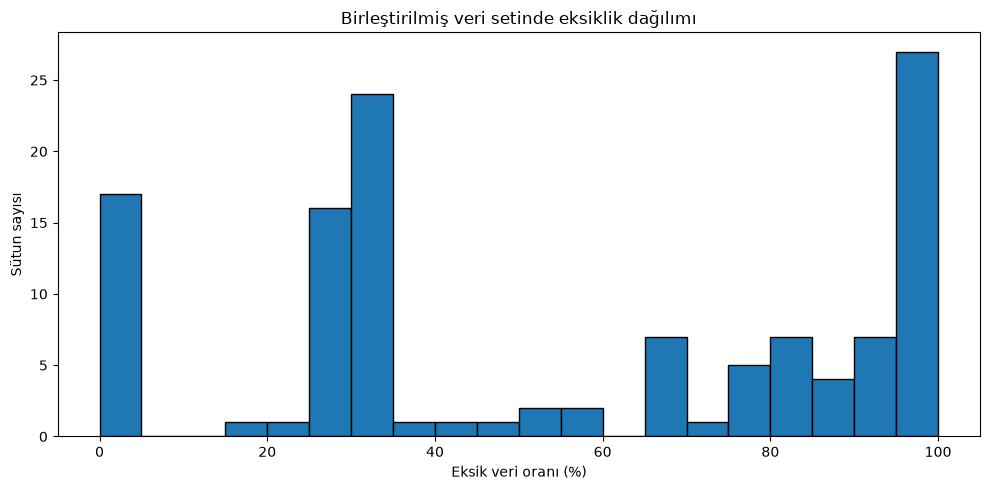

Toplam sütun: 124
Eksiksiz sütun: 12
Eksikliği %50'den fazla sütun: 62
Eksikliği %90'dan fazla sütun: 34


In [15]:

import matplotlib.pyplot as plt

missing_percent = (
    merged_df.isna().mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.hist(
    missing_percent,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Eksik veri oranı (%)")
plt.ylabel("Sütun sayısı")
plt.title("Birleştirilmiş veri setinde eksiklik dağılımı")
plt.tight_layout()
plt.show()

print("Toplam sütun:", len(merged_df.columns))
print("Eksiksiz sütun:", (missing_percent == 0).sum())
print("Eksikliği %50'den fazla sütun:", (missing_percent > 50).sum())
print("Eksikliği %90'dan fazla sütun:", (missing_percent > 90).sum())


In [16]:

candidate_features = [
    "RIDAGEYR",  # Yaş
    "RIAGENDR",  # Cinsiyet
    "RIDRETH3",  # Irk/etnik grup kodu
    "DMDEDUC2",  # Eğitim düzeyi
    "INDFMPIR",  # Gelir-yoksulluk oranı
    "BMXWT",     # Ağırlık
    "BMXHT",     # Boy
    "BMXBMI",    # Vücut kitle indeksi
    "BMXWAIST",  # Bel çevresi
    "BPQ020",    # Yüksek tansiyon tanısı
    "BPQ080",    # Yüksek kolesterol tanısı
    "DIQ010",    # Diyabet tanısı
    "PAQ605",    # Şiddetli iş/aktivite düzeyiyle ilişkili değişken
    "SLD012",    # İş günleri/okul günleri uyku süresi
    "SMQ020",    # En az 100 sigara içme geçmişi
]

available_features = [
    col for col in candidate_features
    if col in merged_df.columns
]

feature_check = pd.DataFrame({
    "Değişken": available_features,
    "Eksik Sayısı": [
        merged_df[col].isna().sum()
        for col in available_features
    ],
    "Eksik Oranı (%)": [
        round(merged_df[col].isna().mean() * 100, 2)
        for col in available_features
    ],
    "Benzersiz Değer Sayısı": [
        merged_df[col].nunique(dropna=True)
        for col in available_features
    ]
})

display(feature_check)


,Değişken,Eksik Sayısı,Eksik Oranı (%),Benzersiz Değer Sayısı
0,RIDAGEYR,0,0.00,81
1,RIAGENDR,0,0.00,2
2,RIDRETH3,0,0.00,6
3,DMDEDUC2,4139,34.69,6
4,INDFMPIR,2041,17.10,471
5,BMXWT,3179,26.64,1389
6,BMXHT,3434,28.78,995
7,BMXBMI,3462,29.01,451
8,BMXWAIST,3743,31.37,1049
9,BPQ020,3435,28.79,4


In [17]:

targets = {
    "Diyabet": "DIQ010",
    "Hipertansiyon": "BPQ020",
    "Yüksek kolesterol": "BPQ080"
}

for name, column in targets.items():
    valid = merged_df[column].isin([1, 2])
    target = merged_df.loc[valid, column]

    yes_count = (target == 1).sum()
    no_count = (target == 2).sum()
    total = len(target)

    print(f"\n--- {name} ---")
    print("Geçerli katılımcı:", total)
    print(f"Evet: {yes_count} (%{yes_count / total * 100:.2f})")
    print(f"Hayır: {no_count} (%{no_count / total * 100:.2f})")



--- Diyabet ---
Geçerli katılımcı: 11452
Evet: 1081 (%9.44)
Hayır: 10371 (%90.56)

--- Hipertansiyon ---
Geçerli katılımcı: 8487
Evet: 2969 (%34.98)
Hayır: 5518 (%65.02)

--- Yüksek kolesterol ---
Geçerli katılımcı: 8444
Evet: 3096 (%36.67)
Hayır: 5348 (%63.33)


In [18]:

# Hipertansiyon için başlangıç özellik adayları
candidate_features = [
    "RIDAGEYR",   # Yaş
    "RIAGENDR",   # Cinsiyet
    "RIDRETH3",   # Etnik grup
    "DMDEDUC2",   # Eğitim düzeyi
    "INDFMPIR",   # Gelir/yoksulluk oranı
    "BMXBMI",     # Vücut kitle indeksi
    "BMXWAIST",   # Bel çevresi
    "SLD012",     # Uyku süresi
    "SMQ020",     # Sigara içme geçmişi
    "PAQ605",     # Fiziksel aktivite değişkeni
    "BPQ080",     # Yüksek kolesterol tanısı
]

target_col = "BPQ020"

available_features = [
    col for col in candidate_features
    if col in merged_df.columns
]

feature_report = pd.DataFrame({
    "Değişken": available_features,
    "Eksik Oranı (%)": [
        round(merged_df[col].isna().mean() * 100, 2)
        for col in available_features
    ],
    "Benzersiz Değer": [
        merged_df[col].nunique(dropna=True)
        for col in available_features
    ]
})

display(feature_report)


,Değişken,Eksik Oranı (%),Benzersiz Değer
0,RIDAGEYR,0.00,81
1,RIAGENDR,0.00,2
2,RIDRETH3,0.00,6
3,DMDEDUC2,34.69,6
4,INDFMPIR,17.10,471
5,BMXBMI,29.01,451
6,BMXWAIST,31.37,1049
7,SLD012,29.71,24
8,SMQ020,31.83,4
9,BPQ080,28.79,4


In [19]:

feature_cols = [
    "RIDAGEYR",
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "INDFMPIR",
    "BMXBMI",
    "BMXWAIST",
    "SLD012",
    "SMQ020",
]

target_col = "BPQ020"

# Yalnızca geçerli hipertansiyon yanıtları: 1 = Evet, 2 = Hayır
valid_mask = merged_df[target_col].isin([1, 2])

X = merged_df.loc[valid_mask, feature_cols].copy()

# Hedefi 1 = hipertansiyon var, 0 = hipertansiyon yok yap
y = (
    merged_df.loc[valid_mask, target_col]
    .map({1: 1, 2: 0})
    .astype(int)
)

print("X boyutu:", X.shape)
print("y boyutu:", y.shape)
print("\nHedef dağılımı:")
print(y.value_counts().rename(index={1: "Hipertansiyon var", 0: "Hipertansiyon yok"}))
print("\nÖzelliklerde eksik değer sayısı:")
print(X.isna().sum())


X boyutu: (8487, 9)
y boyutu: (8487,)

Hedef dağılımı:
BPQ020
Hipertansiyon yok    5518
Hipertansiyon var    2969
Name: count, dtype: int64

Özelliklerde eksik değer sayısı:
RIDAGEYR       0
RIAGENDR       0
RIDRETH3       0
DMDEDUC2     704
INDFMPIR    1431
BMXBMI      1979
BMXWAIST    2204
SLD012       109
SMQ020       363
dtype: int64


In [20]:

categorical_cols = [
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "SMQ020",
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(X[col].value_counts(dropna=False).sort_index())



--- RIAGENDR ---
RIAGENDR
1.0    3821
2.0    4666
Name: count, dtype: int64

--- RIDRETH3 ---
RIDRETH3
1.0     657
2.0     879
3.0    4830
4.0    1089
6.0     463
7.0     569
Name: count, dtype: int64

--- DMDEDUC2 ---
DMDEDUC2
1.0     373
2.0     666
3.0    1749
4.0    2367
5.0    2617
9.0      11
NaN     704
Name: count, dtype: int64

--- SMQ020 ---
SMQ020
1.0    3240
2.0    4870
7.0       7
9.0       7
NaN     363
Name: count, dtype: int64


In [21]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

# Verinin kopyasını al
X_model = X.copy()

# Özel yanıt kodlarını eksik değer olarak işaretle
X_model["DMDEDUC2"] = X_model["DMDEDUC2"].replace([7, 9], float("nan"))
X_model["SMQ020"] = X_model["SMQ020"].replace([7, 9], float("nan"))

numeric_cols = [
    "INDFMPIR",
    "BMXBMI",
    "BMXWAIST",
    "SLD012",
]

categorical_cols = [
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "SMQ020",
]

# Eğitim/test ayrımı
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Sayısal özelliklerde medyan, kategoriklerde en sık değer
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols),
    ("age", "passthrough", ["RIDAGEYR"]),
])

# İlk model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Eğitim örneği:", len(X_train))
print("Test örneği:", len(X_test))
print("Model eğitildi.")


Eğitim örneği: 6789
Test örneği: 1698
Model eğitildi.


In [22]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Test verisi üzerinde tahmin
y_pred = model.predict(X_test)

# Hipertansiyon sınıfına ait olasılık
y_proba = model.predict_proba(X_test)[:, 1]

# Performans metrikleri
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))

print("\nSınıflandırma raporu:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Hipertansiyon yok", "Hipertansiyon var"]
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.7279
Precision: 0.615
Recall: 0.5943
F1-score: 0.6045
ROC-AUC: 0.7842

Sınıflandırma raporu:
                   precision    recall  f1-score   support

Hipertansiyon yok       0.79      0.80      0.79      1104
Hipertansiyon var       0.61      0.59      0.60       594

         accuracy                           0.73      1698
        macro avg       0.70      0.70      0.70      1698
     weighted avg       0.73      0.73      0.73      1698

Confusion matrix:
[[883 221]
 [241 353]]


In [23]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest sonuçları")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred), 4))
print("Recall:", round(recall_score(y_test, rf_pred), 4))
print("F1-score:", round(f1_score(y_test, rf_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_proba), 4))


Random Forest sonuçları
Accuracy: 0.7061
Precision: 0.5566
Recall: 0.7862
F1-score: 0.6518
ROC-AUC: 0.7773


In [24]:

from sklearn.metrics import confusion_matrix, classification_report

print("Confusion matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nSınıflandırma raporu:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Hipertansiyon yok", "Hipertansiyon var"]
))


Confusion matrix:
[[732 372]
 [127 467]]

Sınıflandırma raporu:
                   precision    recall  f1-score   support

Hipertansiyon yok       0.85      0.66      0.75      1104
Hipertansiyon var       0.56      0.79      0.65       594

         accuracy                           0.71      1698
        macro avg       0.70      0.72      0.70      1698
     weighted avg       0.75      0.71      0.71      1698



In [25]:

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

rf_proba = rf_model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    pred = (rf_proba >= threshold).astype(int)

    threshold_results.append({
        "Eşik": threshold,
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))


,Eşik,Precision,Recall,F1-score
0,0.30,0.474,0.907,0.623
1,0.35,0.499,0.889,0.639
2,0.40,0.516,0.857,0.644
3,0.45,0.531,0.820,0.645
4,0.50,0.557,0.786,0.652
5,0.55,0.565,0.727,0.636
6,0.60,0.580,0.625,0.601


In [26]:

import pandas as pd

# Ön işleme sonrası özellik isimleri
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Random Forest özellik önemleri
importances = (
    rf_model.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Özellik": feature_names,
    "Önem": importances
}).sort_values("Önem", ascending=False)

display(importance_df.head(15).round(4))


,Özellik,Önem
19,age__RIDAGEYR,0.4393
2,numeric__BMXWAIST,0.1433
1,numeric__BMXBMI,0.1240
0,numeric__INDFMPIR,0.0827
3,numeric__SLD012,0.0597
16,categorical__DMDEDUC2_5.0,0.0285
18,categorical__SMQ020_2.0,0.0150
17,categorical__SMQ020_1.0,0.0141
9,categorical__RIDRETH3_4.0,0.0126
8,categorical__RIDRETH3_3.0,0.0122


In [27]:

try:
    import shap
    print("SHAP sürümü:", shap.__version__)
except ImportError:
    print("SHAP kurulu değil. Kurulum gerekli.")


c:\BitirmeProjesi\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP sürümü: 0.53.0


In [28]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [29]:
import shap

print("SHAP sürümü:", shap.__version__)

SHAP sürümü: 0.53.0


In [30]:

import shap
import pandas as pd
import matplotlib.pyplot as plt

# Test verisinden örneklem seç
X_shap = X_test.sample(
    n=min(200, len(X_test)),
    random_state=42
)

# Modelin ön işleme adımlarını uygula
X_shap_transformed = (
    rf_model.named_steps["preprocessor"]
    .transform(X_shap)
)

# Dönüştürülmüş sütun isimleri
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Eğitilmiş Random Forest
rf_classifier = rf_model.named_steps["classifier"]

# SHAP açıklayıcısı
explainer = shap.TreeExplainer(rf_classifier)

# SHAP değerleri
shap_values = explainer.shap_values(
    X_shap_transformed
)

print("SHAP hesaplaması tamamlandı.")
print("Dönüştürülmüş veri boyutu:", X_shap_transformed.shape)
print("SHAP değerlerinin boyutu:", getattr(shap_values, "shape", None))


SHAP hesaplaması tamamlandı.
Dönüştürülmüş veri boyutu: (200, 20)
SHAP değerlerinin boyutu: (200, 20, 2)


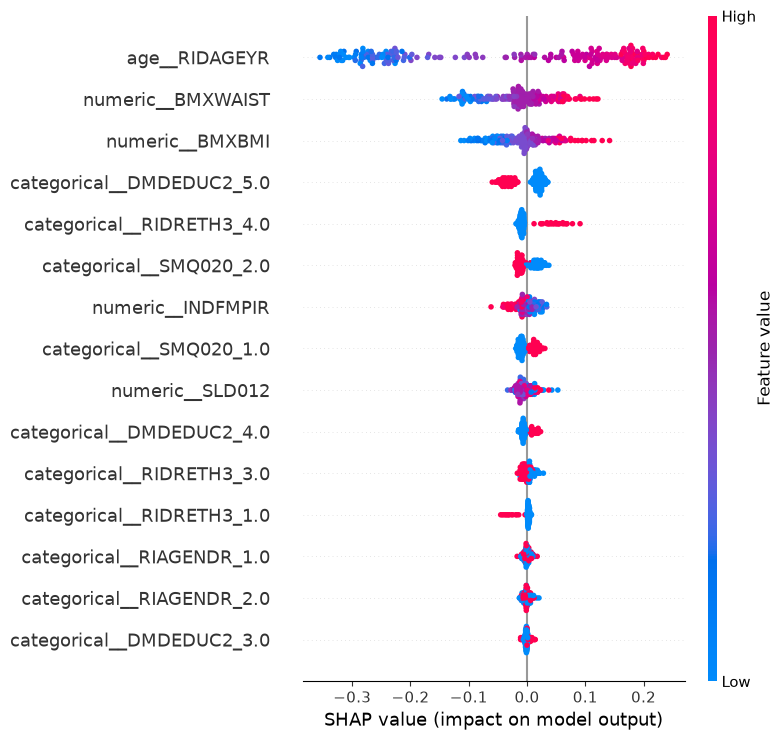

In [31]:

# Hipertansiyon var sınıfının SHAP değerleri
shap_values_positive = shap_values[:, :, 1]

# Genel özellik etkilerini göster
shap.summary_plot(
    shap_values_positive,
    X_shap_transformed,
    feature_names=feature_names,
    max_display=15,
    show=True
)


Gerçek etiket: 0
Model tahmini: Hipertansiyon var
Modelin pozitif sınıf olasılığı: 0.743


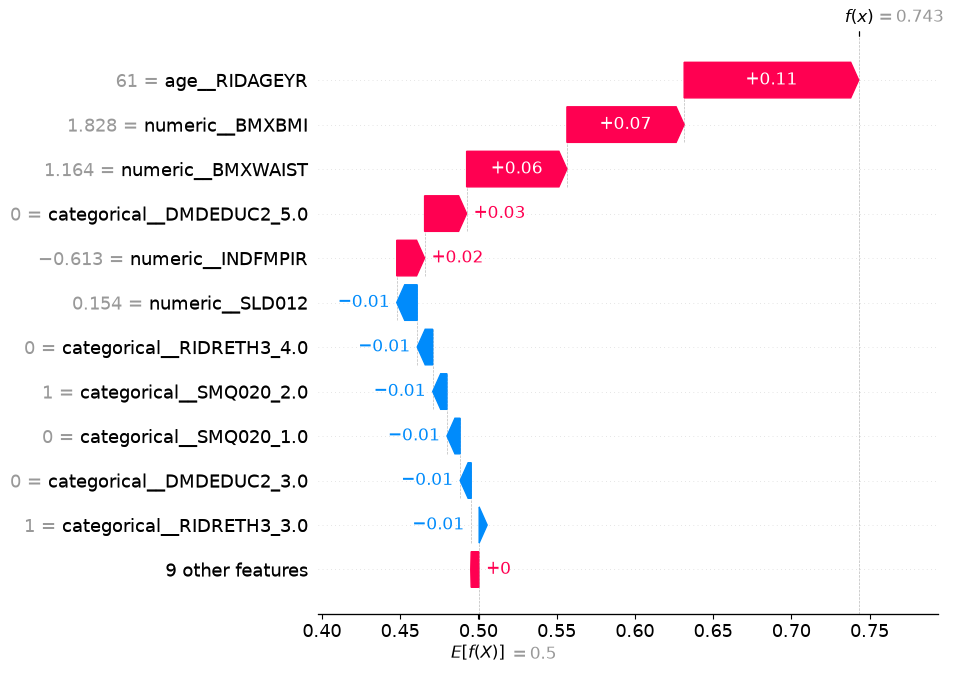

In [32]:

# Açıklamak için bir test katılımcısı seç
sample_index = 0

sample = X_shap.iloc[[sample_index]]
sample_transformed = X_shap_transformed[sample_index:sample_index + 1]

# Model tahmini ve olasılığı
prediction = rf_model.predict(sample)[0]
probability = rf_model.predict_proba(sample)[0, 1]

print("Gerçek etiket:", y_test.loc[sample.index[0]]
      if sample.index[0] in y_test.index else "Bu örnek y_test indeksinde değil")

print("Model tahmini:", "Hipertansiyon var" if prediction == 1
      else "Hipertansiyon yok")
print("Modelin pozitif sınıf olasılığı:", round(probability, 3))

# Tek katılımcının SHAP açıklaması

# Pozitif sınıf için SHAP açıklamasını oluştur
single_explanation = shap.Explanation(
    values=shap_values_positive[sample_index],
    base_values=explainer.expected_value[1],
    data=sample_transformed[0],
    feature_names=feature_names
)

shap.plots.waterfall(
    single_explanation,
    max_display=12
)



In [33]:

# Diyabet modeli için hedef değişken
target_col = "DIQ010"

# Hipertansiyon modelinde kullandığımız temel özellikler
diabetes_features = [
    "RIDAGEYR",
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "INDFMPIR",
    "BMXBMI",
    "BMXWAIST",
    "SLD012",
    "SMQ020",
]

# Yalnızca geçerli diyabet yanıtları
valid_mask = merged_df[target_col].isin([1, 2])

X_diabetes = merged_df.loc[
    valid_mask, diabetes_features
].copy()

# 1 = diyabet var, 0 = diyabet yok
y_diabetes = (
    merged_df.loc[valid_mask, target_col]
    .map({1: 1, 2: 0})
    .astype(int)
)

print("X boyutu:", X_diabetes.shape)
print("y boyutu:", y_diabetes.shape)

print("\nHedef dağılımı:")
print(
    y_diabetes.value_counts()
    .rename(index={
        1: "Diyabet var",
        0: "Diyabet yok"
    })
)

print("\nEksik değer sayıları:")
print(X_diabetes.isna().sum())


X boyutu: (11452, 9)
y boyutu: (11452,)

Hedef dağılımı:
DIQ010
Diyabet yok    10371
Diyabet var     1081
Name: count, dtype: int64

Eksik değer sayıları:
RIDAGEYR       0
RIAGENDR       0
RIDRETH3       0
DMDEDUC2    3929
INDFMPIR    1968
BMXBMI      3212
BMXWAIST    3484
SLD012      3330
SMQ020      3591
dtype: int64


In [34]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

# Özelliklerin kopyası
X_diabetes_model = X_diabetes.copy()

# Özel yanıt kodlarını eksik olarak işaretle
X_diabetes_model["DMDEDUC2"] = (
    X_diabetes_model["DMDEDUC2"].replace([7, 9], float("nan"))
)

X_diabetes_model["SMQ020"] = (
    X_diabetes_model["SMQ020"].replace([7, 9], float("nan"))
)

numeric_cols = [
    "INDFMPIR",
    "BMXBMI",
    "BMXWAIST",
    "SLD012",
]

categorical_cols = [
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "SMQ020",
]

X_train_diab, X_test_diab, y_train_diab, y_test_diab = (
    train_test_split(
        X_diabetes_model,
        y_diabetes,
        test_size=0.20,
        random_state=42,
        stratify=y_diabetes
    )
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

diabetes_preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols),
    ("age", "passthrough", ["RIDAGEYR"]),
])

print("Eğitim örneği:", len(X_train_diab))
print("Test örneği:", len(X_test_diab))
print("Eğitimde diyabetli:", int(y_train_diab.sum()))
print("Testte diyabetli:", int(y_test_diab.sum()))


Eğitim örneği: 9161
Test örneği: 2291
Eğitimde diyabetli: 865
Testte diyabetli: 216


In [35]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

diabetes_lr = Pipeline([
    ("preprocessor", diabetes_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Modeli eğit
diabetes_lr.fit(X_train_diab, y_train_diab)

# Test setinde tahmin yap
y_pred_diab = diabetes_lr.predict(X_test_diab)
y_proba_diab = diabetes_lr.predict_proba(X_test_diab)[:, 1]

print("Diyabet - Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test_diab, y_pred_diab), 4))
print("Precision:", round(precision_score(y_test_diab, y_pred_diab), 4))
print("Recall:", round(recall_score(y_test_diab, y_pred_diab), 4))
print("F1-score:", round(f1_score(y_test_diab, y_pred_diab), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_diab, y_proba_diab), 4))

print("\nSınıflandırma raporu:")
print(classification_report(
    y_test_diab,
    y_pred_diab,
    target_names=["Diyabet yok", "Diyabet var"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test_diab, y_pred_diab))


Diyabet - Logistic Regression
Accuracy: 0.7224
Precision: 0.2294
Recall: 0.8241
F1-score: 0.3589
ROC-AUC: 0.8487

Sınıflandırma raporu:
              precision    recall  f1-score   support

 Diyabet yok       0.97      0.71      0.82      2075
 Diyabet var       0.23      0.82      0.36       216

    accuracy                           0.72      2291
   macro avg       0.60      0.77      0.59      2291
weighted avg       0.90      0.72      0.78      2291

Confusion matrix:
[[1477  598]
 [  38  178]]


In [36]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

diabetes_rf = Pipeline([
    ("preprocessor", diabetes_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

diabetes_rf.fit(X_train_diab, y_train_diab)

y_pred_rf_diab = diabetes_rf.predict(X_test_diab)
y_proba_rf_diab = diabetes_rf.predict_proba(X_test_diab)[:, 1]

print("Diyabet - Random Forest")
print("Accuracy:", round(accuracy_score(y_test_diab, y_pred_rf_diab), 4))
print("Precision:", round(precision_score(y_test_diab, y_pred_rf_diab), 4))
print("Recall:", round(recall_score(y_test_diab, y_pred_rf_diab), 4))
print("F1-score:", round(f1_score(y_test_diab, y_pred_rf_diab), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_diab, y_proba_rf_diab), 4))


Diyabet - Random Forest
Accuracy: 0.7647
Precision: 0.2399
Recall: 0.6898
F1-score: 0.356
ROC-AUC: 0.842


In [37]:
print("Random Forest - Sınıflandırma raporu")
print(classification_report(
    y_test_diab,
    y_pred_rf_diab,
    target_names=["Diyabet yok", "Diyabet var"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test_diab, y_pred_rf_diab))

Random Forest - Sınıflandırma raporu
              precision    recall  f1-score   support

 Diyabet yok       0.96      0.77      0.86      2075
 Diyabet var       0.24      0.69      0.36       216

    accuracy                           0.76      2291
   macro avg       0.60      0.73      0.61      2291
weighted avg       0.89      0.76      0.81      2291

Confusion matrix:
[[1603  472]
 [  67  149]]


In [38]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

# Eğitim verisini yeniden ayır: %80 eğitim, %20 doğrulama
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_diab,
    y_train_diab,
    test_size=0.20,
    random_state=42,
    stratify=y_train_diab
)

# Modelleri yalnızca yeni eğitim alt kümesinde eğit
lr_val_model = clone(diabetes_lr)
rf_val_model = clone(diabetes_rf)

lr_val_model.fit(X_fit, y_fit)
rf_val_model.fit(X_fit, y_fit)

models = {
    "Logistic Regression": lr_val_model,
    "Random Forest": rf_val_model
}

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

for name, model in models.items():
    probabilities = model.predict_proba(X_val)[:, 1]

    print(f"\n{name}")
    print("Eşik | Precision | Recall | F1")

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        precision = precision_score(
            y_val, predictions, zero_division=0
        )
        recall = recall_score(
            y_val, predictions, zero_division=0
        )
        f1 = f1_score(
            y_val, predictions, zero_division=0
        )

        print(
            f"{threshold:.2f} | "
            f"{precision:.3f} | "
            f"{recall:.3f} | "
            f"{f1:.3f}"
        )


Logistic Regression
Eşik | Precision | Recall | F1
0.30 | 0.198 | 0.965 | 0.329
0.35 | 0.207 | 0.942 | 0.339
0.40 | 0.217 | 0.925 | 0.351
0.45 | 0.225 | 0.890 | 0.359
0.50 | 0.241 | 0.855 | 0.376
0.55 | 0.261 | 0.827 | 0.397
0.60 | 0.285 | 0.798 | 0.420

Random Forest
Eşik | Precision | Recall | F1
0.30 | 0.218 | 0.942 | 0.355
0.35 | 0.233 | 0.919 | 0.371
0.40 | 0.245 | 0.879 | 0.383
0.45 | 0.262 | 0.844 | 0.400
0.50 | 0.285 | 0.809 | 0.422
0.55 | 0.290 | 0.688 | 0.408
0.60 | 0.313 | 0.566 | 0.403


In [39]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

thresholds = {
    "Logistic Regression": 0.60,
    "Random Forest": 0.50
}

test_models = {
    "Logistic Regression": (diabetes_lr, y_proba_diab),
    "Random Forest": (diabetes_rf, y_proba_rf_diab)
}

for name, (model, probabilities) in test_models.items():
    threshold = thresholds[name]
    predictions = (probabilities >= threshold).astype(int)

    print(f"\n{name} | Eşik: {threshold}")
    print("Precision:", round(
        precision_score(y_test_diab, predictions), 4
    ))
    print("Recall:", round(
        recall_score(y_test_diab, predictions), 4
    ))
    print("F1-score:", round(
        f1_score(y_test_diab, predictions), 4
    ))
    print("ROC-AUC:", round(
        roc_auc_score(y_test_diab, probabilities), 4
    ))

    print("Confusion matrix:")
    print(confusion_matrix(y_test_diab, predictions))

    print(classification_report(
        y_test_diab,
        predictions,
        target_names=["Diyabet yok", "Diyabet var"],
        zero_division=0
    ))


Logistic Regression | Eşik: 0.6
Precision: 0.255
Recall: 0.713
F1-score: 0.3756
ROC-AUC: 0.8487
Confusion matrix:
[[1625  450]
 [  62  154]]
              precision    recall  f1-score   support

 Diyabet yok       0.96      0.78      0.86      2075
 Diyabet var       0.25      0.71      0.38       216

    accuracy                           0.78      2291
   macro avg       0.61      0.75      0.62      2291
weighted avg       0.90      0.78      0.82      2291


Random Forest | Eşik: 0.5
Precision: 0.2399
Recall: 0.6898
F1-score: 0.356
ROC-AUC: 0.842
Confusion matrix:
[[1603  472]
 [  67  149]]
              precision    recall  f1-score   support

 Diyabet yok       0.96      0.77      0.86      2075
 Diyabet var       0.24      0.69      0.36       216

    accuracy                           0.76      2291
   macro avg       0.60      0.73      0.61      2291
weighted avg       0.89      0.76      0.81      2291



In [40]:
import pandas as pd
import numpy as np

# Eğitilmiş Logistic Regression modelinin parçaları
lr_classifier = diabetes_lr.named_steps["classifier"]
lr_preprocessor = diabetes_lr.named_steps["preprocessor"]

# Dönüştürülmüş özellik isimleri ve katsayılar
feature_names = lr_preprocessor.get_feature_names_out()
coefficients = lr_classifier.coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds_Ratio": np.exp(coefficients)
})

coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()

coef_df.sort_values(
    "Abs_Coefficient",
    ascending=False
).head(15)

,Feature,Coefficient,Odds_Ratio,Abs_Coefficient
16,categorical__DMDEDUC2_5.0,-0.848707,0.427968,0.848707
18,categorical__SMQ020_2.0,-0.724200,0.484712,0.724200
5,categorical__RIAGENDR_2.0,-0.713826,0.489767,0.713826
8,categorical__RIDRETH3_3.0,-0.644358,0.525000,0.644358
4,categorical__RIAGENDR_1.0,-0.534889,0.585734,0.534889
17,categorical__SMQ020_1.0,-0.524515,0.591843,0.524515
15,categorical__DMDEDUC2_4.0,-0.443695,0.641661,0.443695
2,numeric__BMXWAIST,0.435443,1.545647,0.435443
12,categorical__DMDEDUC2_1.0,0.383046,1.466746,0.383046
7,categorical__RIDRETH3_2.0,-0.368432,0.691818,0.368432


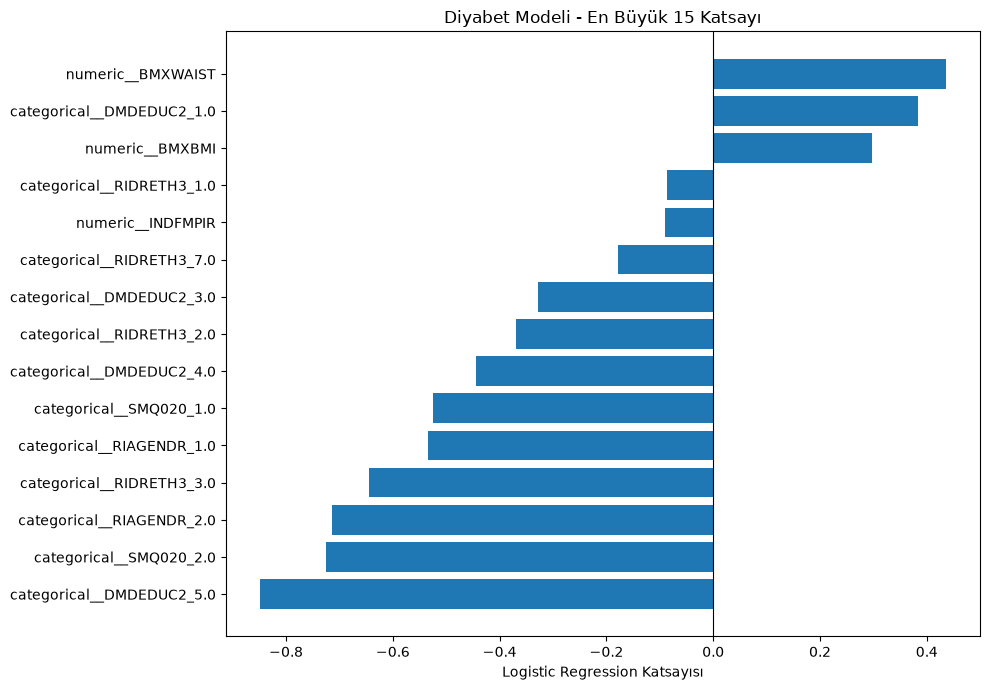

In [41]:
import matplotlib.pyplot as plt

top_features = (
    coef_df.sort_values("Abs_Coefficient", ascending=False)
           .head(15)
           .sort_values("Coefficient")
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Logistic Regression Katsayısı")
plt.title("Diyabet Modeli - En Büyük 15 Katsayı")
plt.tight_layout()
plt.show()

In [42]:
import shap

# Ön işleme uygulanmış özellikler
X_shap_diab = X_test_diab.sample(
    n=min(200, len(X_test_diab)),
    random_state=42
)

X_shap_transformed = (
    diabetes_lr
    .named_steps["preprocessor"]
    .transform(X_shap_diab)
)

feature_names = (
    diabetes_lr
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Logistic Regression için SHAP açıklayıcısı
explainer_diab = shap.LinearExplainer(
    diabetes_lr.named_steps["classifier"],
    diabetes_lr.named_steps["preprocessor"].transform(X_train_diab)
)

shap_values_diab = explainer_diab(
    X_shap_transformed
)

print("SHAP shape:", shap_values_diab.values.shape)
print("Özellik sayısı:", len(feature_names))

Background dataset has 9161 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=9161 when initializing the masker.


SHAP shape: (200, 20)
Özellik sayısı: 20


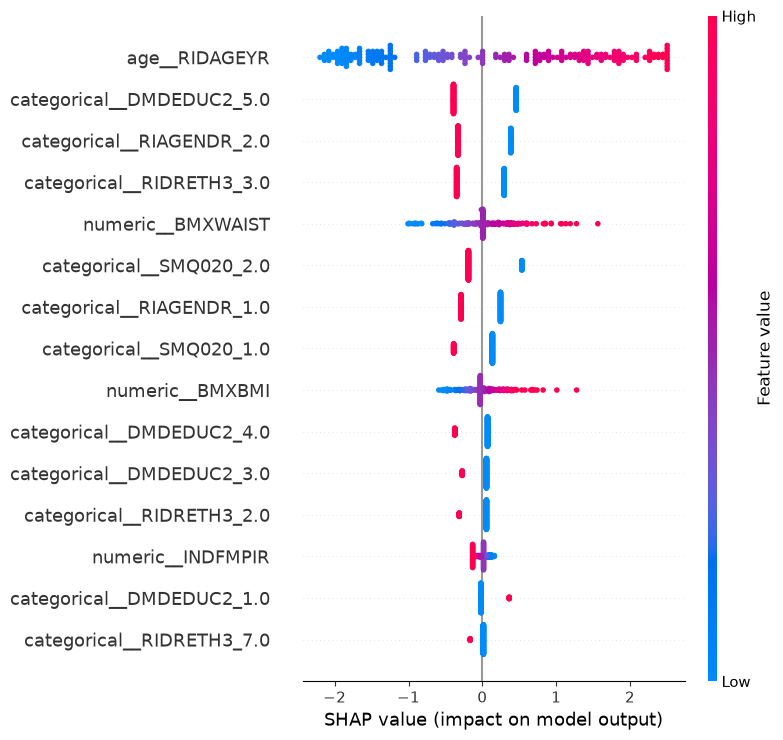

In [43]:
shap.summary_plot(
    shap_values_diab.values,
    X_shap_transformed,
    feature_names=feature_names,
    max_display=15
)

Gerçek etiket: 0
Tahmin: 0
Modelin pozitif sınıf olasılığı: 0.2387


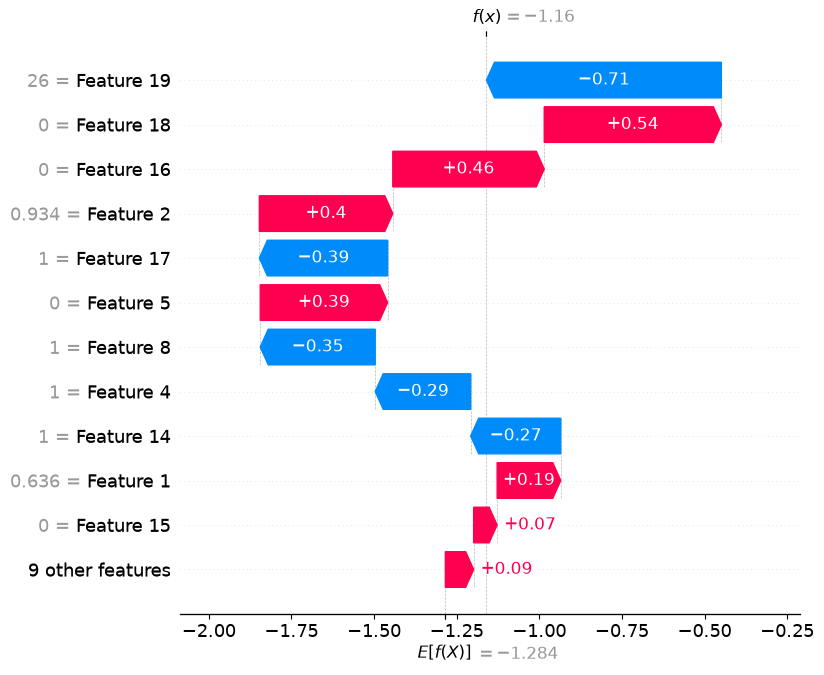

In [44]:
sample_index = 0

sample = X_shap_diab.iloc[[sample_index]]
sample_shap = shap_values_diab[sample_index]

prediction = diabetes_lr.predict(sample)[0]
probability = diabetes_lr.predict_proba(sample)[0, 1]

print("Gerçek etiket:", y_test_diab.loc[sample.index].iloc[0])
print("Tahmin:", prediction)
print("Modelin pozitif sınıf olasılığı:", round(probability, 4))

shap.plots.waterfall(sample_shap, max_display=12)

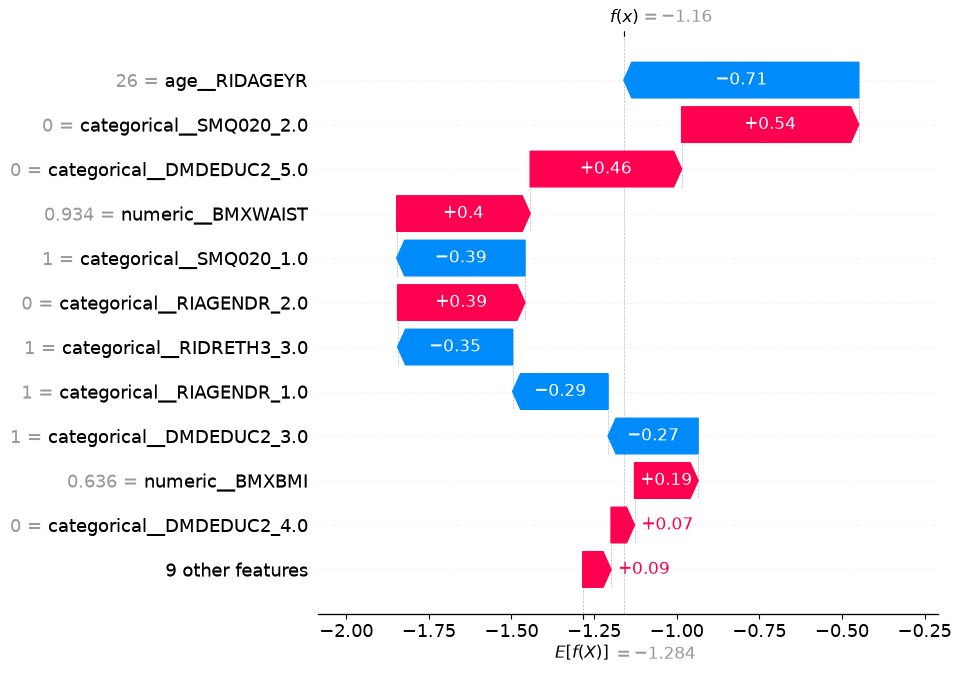

In [45]:
# Tek bir örnek seç
sample_index = 0

sample = X_shap_diab.iloc[[sample_index]]

# Modelin ön işleme adımından geçir
sample_transformed = diabetes_lr.named_steps[
    "preprocessor"
].transform(sample)

# Özellik isimlerini al
feature_names = diabetes_lr.named_steps[
    "preprocessor"
].get_feature_names_out()

# SHAP değerlerini al
sample_values = shap_values_diab.values[sample_index]
base_value = shap_values_diab.base_values[sample_index]

# Açıklamayı özellik isimleriyle yeniden oluştur
sample_explanation = shap.Explanation(
    values=sample_values,
    base_values=base_value,
    data=sample_transformed.toarray()[0]
        if hasattr(sample_transformed, "toarray")
        else sample_transformed[0],
    feature_names=list(feature_names)
)

shap.plots.waterfall(sample_explanation, max_display=12)

In [46]:
import pandas as pd

# Mevcut birleştirilmiş veride bulunan olası hedefler
target_candidates = {
    "Diabetes": "DIQ010",
    "Hypertension": "BPQ020",
    "High cholesterol": "BPQ080",
    "Arthritis": "MCQ160A",
    "Heart failure": "MCQ160B",
    "Coronary heart disease": "MCQ160C",
    "Angina": "MCQ160D",
    "Heart attack": "MCQ160E",
    "Stroke": "MCQ160F",
    "Chronic bronchitis": "MCQ160L",
    "Thyroid problem": "MCQ160M",
    "Liver condition": "MCQ160P",
    "Cancer": "MCQ220"
}

results = []

for disease, col in target_candidates.items():
    if col not in merged_df.columns:
        continue

    s = merged_df[col]

    # NHANES'te 1=Yes, 2=No olarak kodlanan hedefler
    valid = s.isin([1, 2])
    yes_count = int((s[valid] == 1).sum())
    no_count = int((s[valid] == 2).sum())
    n = yes_count + no_count

    results.append({
        "Disease": disease,
        "Column": col,
        "Valid_N": n,
        "Yes": yes_count,
        "No": no_count,
        "Positive_Rate_%": round(100 * yes_count / n, 2)
            if n else None,
        "Missing_or_special": int((~valid).sum())
    })

target_audit = pd.DataFrame(results)

target_audit.sort_values(
    "Valid_N", ascending=False
).reset_index(drop=True)

,Disease,Column,Valid_N,Yes,No,Positive_Rate_%,Missing_or_special
0,Diabetes,DIQ010,11452,1081,10371,9.44,481
1,Hypertension,BPQ020,8487,2969,5518,34.98,3446
2,High cholesterol,BPQ080,8444,3096,5348,36.67,3489
3,Cancer,MCQ220,7800,1169,6631,14.99,4133
4,Heart attack,MCQ160E,7794,332,7462,4.26,4139
5,Chronic bronchitis,MCQ160L,7794,425,7369,5.45,4139
6,Liver condition,MCQ160P,7793,567,7226,7.28,4140
7,Heart failure,MCQ160B,7791,343,7448,4.40,4142
8,Arthritis,MCQ160A,7790,2532,5258,32.50,4143
9,Thyroid problem,MCQ160M,7787,1053,6734,13.52,4146


In [47]:
candidate_features = [
    "RIDAGEYR",  # Yaş
    "RIAGENDR",  # Cinsiyet
    "BMXBMI",    # Vücut kitle indeksi
    "BMXWAIST",  # Bel çevresi
    "SLD012",    # İş günlerinde uyku süresi
    "SMQ020",    # Yaşam boyu sigara kullanımı
    "INDFMPIR",  # Gelir-yoksulluk oranı
    "DIQ010",    # Diyabet hedefi
    "BPQ020",    # Hipertansiyon hedefi
    "BPQ080",    # Yüksek kolesterol hedefi
    "MCQ220",    # Kanser hedefi
    "MCQ160A",  # Artrit hedefi
    "MCQ160M"   # Tiroid hedefi
]

available_features = [
    col for col in candidate_features
    if col in merged_df.columns
]

feature_audit = pd.DataFrame({
    "Feature": available_features,
    "Missing_Count": [
        merged_df[col].isna().sum()
        for col in available_features
    ],
    "Missing_Rate_%": [
        round(merged_df[col].isna().mean() * 100, 2)
        for col in available_features
    ],
    "Unique_Values": [
        merged_df[col].nunique(dropna=True)
        for col in available_features
    ]
})

feature_audit.sort_values(
    "Missing_Rate_%", ascending=False
).reset_index(drop=True)

,Feature,Missing_Count,Missing_Rate_%,Unique_Values
0,MCQ160A,4126,34.58,3
1,MCQ160M,4127,34.58,4
2,MCQ220,4126,34.58,4
3,SMQ020,3798,31.83,4
4,BMXWAIST,3743,31.37,1049
5,SLD012,3545,29.71,24
6,BMXBMI,3462,29.01,451
7,BPQ020,3435,28.79,4
8,BPQ080,3435,28.79,4
9,INDFMPIR,2041,17.10,471


In [48]:
columns_to_check = [
    "DIQ010",
    "BPQ020",
    "BPQ080",
    "MCQ160A",
    "MCQ160M",
    "MCQ220",
    "SMQ020",
    "DMDEDUC2",
    "SLD012"
]

for col in columns_to_check:
    if col in merged_df.columns:
        print(f"\n--- {col} ---")
        print(merged_df[col].value_counts(dropna=False).sort_index())


--- DIQ010 ---
DIQ010
1.0     1081
2.0    10371
3.0      284
9.0        4
NaN      193
Name: count, dtype: int64

--- BPQ020 ---
BPQ020
1.0    2969
2.0    5518
7.0       1
9.0      10
NaN    3435
Name: count, dtype: int64

--- BPQ080 ---
BPQ080
1.0    3096
2.0    5348
7.0       1
9.0      53
NaN    3435
Name: count, dtype: int64

--- MCQ160A ---
MCQ160A
1.0    2532
2.0    5258
9.0      17
NaN    4126
Name: count, dtype: int64

--- MCQ160M ---
MCQ160M
1.0    1053
2.0    6734
7.0       1
9.0      18
NaN    4127
Name: count, dtype: int64

--- MCQ220 ---
MCQ220
1.0    1169
2.0    6631
7.0       2
9.0       5
NaN    4126
Name: count, dtype: int64

--- SMQ020 ---
SMQ020
1.0    3243
2.0    4878
7.0       7
9.0       7
NaN    3798
Name: count, dtype: int64

--- DMDEDUC2 ---
DMDEDUC2
1.0     373
2.0     666
3.0    1749
4.0    2370
5.0    2625
9.0      11
NaN    4139
Name: count, dtype: int64

--- SLD012 ---
SLD012
2.0       33
3.0       43
3.5       27
4.0      125
4.5       58
5.0      277
5.

In [49]:
check_cols = [
    "MCQ160A", "MCQ160M", "MCQ220",
    "SMQ020", "DMDEDUC2", "SLD012"
]

for col in check_cols:
    if col in merged_df.columns:
        print(f"\n--- {col} ---")
        print(
            merged_df[col]
            .value_counts(dropna=False)
            .sort_index()
            .to_string()
        )


--- MCQ160A ---
MCQ160A
1.0    2532
2.0    5258
9.0      17
NaN    4126

--- MCQ160M ---
MCQ160M
1.0    1053
2.0    6734
7.0       1
9.0      18
NaN    4127

--- MCQ220 ---
MCQ220
1.0    1169
2.0    6631
7.0       2
9.0       5
NaN    4126

--- SMQ020 ---
SMQ020
1.0    3243
2.0    4878
7.0       7
9.0       7
NaN    3798

--- DMDEDUC2 ---
DMDEDUC2
1.0     373
2.0     666
3.0    1749
4.0    2370
5.0    2625
9.0      11
NaN    4139

--- SLD012 ---
SLD012
2.0       33
3.0       43
3.5       27
4.0      125
4.5       58
5.0      277
5.5      165
6.0      586
6.5      422
7.0     1218
7.5      905
8.0     1729
8.5      770
9.0      990
9.5      248
10.0     410
10.5      72
11.0     165
11.5      20
12.0      50
12.5       9
13.0      26
13.5       3
14.0      37
NaN     3545


In [50]:
core_targets = [
    "DIQ010",   # Diyabet
    "BPQ020",   # Hipertansiyon
    "BPQ080",   # Yüksek kolesterol
    "MCQ160A"   # Artrit
]

core_features = [
    "RIDAGEYR",
    "RIAGENDR",
    "BMXBMI",
    "BMXWAIST",
    "SLD012",
    "SMQ020"
]

# Yalnızca tabloda gerçekten bulunan sütunları kullan
targets = [c for c in core_targets if c in merged_df.columns]
features = [c for c in core_features if c in merged_df.columns]

print("Hedef başına geçerli etiket sayısı:")
for col in targets:
    print(col, int(merged_df[col].isin([1, 2]).sum()))

print("\nTüm hedefleri geçerli olan katılımcı sayısı:")
all_targets_valid = merged_df[targets].apply(
    lambda col: col.isin([1, 2])
).all(axis=1)
print(int(all_targets_valid.sum()))

print("\nTüm ortak özellikleri dolu olan katılımcı sayısı:")
all_features_present = merged_df[features].notna().all(axis=1)
print(int(all_features_present.sum()))

print("\nHedefleri ve ortak özellikleri geçerli katılımcı sayısı:")
print(int((all_targets_valid & all_features_present).sum()))

Hedef başına geçerli etiket sayısı:
DIQ010 11452
BPQ020 8487
BPQ080 8444
MCQ160A 7790

Tüm hedefleri geçerli olan katılımcı sayısı:
7465

Tüm ortak özellikleri dolu olan katılımcı sayısı:
5944

Hedefleri ve ortak özellikleri geçerli katılımcı sayısı:
5443


In [51]:
import joblib

joblib.dump(diabetes_rf, "diabetes_rf.joblib")

print("Model kaydedildi.")

Model kaydedildi.


In [52]:
import pandas as pd
import joblib

# Eğitilmiş modeli yükle
model = joblib.load("diabetes_rf.joblib")

# Kullanıcı bilgilerini al
age = int(input("Yaş: "))
sex = int(input("Cinsiyet (1=Erkek, 2=Kadın): "))
race = int(input("NHANES etnik köken kodu (1-7): "))
education = int(input("Eğitim kodu (1-5, bilinmiyorsa 0): "))
income = float(input("Gelir-yoksulluk oranı (bilmiyorsan -1): "))
bmi = float(input("BMI: "))
waist = float(input("Bel çevresi (cm): "))
sleep = float(input("Günlük uyku süresi (saat): "))
smoking = int(input("Daha önce en az 100 sigara içti mi? (1=Evet, 2=Hayır): "))

# Bilinmeyen değerleri eksik olarak işaretle
if education == 0:
    education = float("nan")

if income < 0:
    income = float("nan")

# Modelin beklediği sütun adlarıyla veriyi hazırla
user_data = pd.DataFrame([{
    "RIDAGEYR": age,
    "RIAGENDR": sex,
    "RIDRETH3": race,
    "DMDEDUC2": education,
    "INDFMPIR": income,
    "BMXBMI": bmi,
    "BMXWAIST": waist,
    "SLD012": sleep,
    "SMQ020": smoking
}])

# Pozitif sınıfın model olasılığını hesapla
probabilities = model.predict_proba(user_data)[0]
positive_index = list(model.classes_).index(1)
probability = probabilities[positive_index]

print(f"\nModelin pozitif sınıf olasılığı: %{probability * 100:.2f}")


Modelin pozitif sınıf olasılığı: %22.07


In [53]:
print("Model sınıfları:", model.classes_)
print("Sınıf olasılıkları:", model.predict_proba(user_data)[0])
print("Tahmin edilen sınıf:", model.predict(user_data)[0])

Model sınıfları: [0 1]
Sınıf olasılıkları: [0.77930477 0.22069523]
Tahmin edilen sınıf: 0


In [54]:
# BMI ve bel çevresini değiştirelim
user_data_test = user_data.copy()

user_data_test["BMXBMI"] = 35
user_data_test["BMXWAIST"] = 115

probabilities_test = model.predict_proba(user_data_test)[0]
positive_index = list(model.classes_).index(1)

print(
    "Yeni pozitif sınıf olasılığı: "
    f"%{probabilities_test[positive_index] * 100:.2f}"
)

Yeni pozitif sınıf olasılığı: %16.36


In [55]:
import pandas as pd

scenarios = {
    "Başlangıç": (27, 90),
    "Yüksek BMI": (35, 90),
    "Yüksek bel çevresi": (27, 115)
}

for name, (bmi, waist) in scenarios.items():
    test_data = user_data.copy()
    test_data["BMXBMI"] = bmi
    test_data["BMXWAIST"] = waist

    probability = model.predict_proba(test_data)[0][1]

    print(f"{name}: %{probability * 100:.2f}")

Başlangıç: %5.04
Yüksek BMI: %12.42
Yüksek bel çevresi: %14.12


In [56]:
import pandas as pd
import numpy as np

def predict_diabetes():
    print("\n=== Diyabet Modeli ===")
    print("Bilmediğin sayısal alanları boş bırakabilirsin.\n")

    age = int(input("Yaş: "))

    sex_input = input("Cinsiyet (Erkek/Kadın): ").strip().lower()
    sex_map = {"erkek": 1, "kadın": 2, "kadin": 2}

    if sex_input not in sex_map:
        print("Cinsiyet için Erkek veya Kadın gir.")
        return

    sex = sex_map[sex_input]

    print("\nEtnik köken kategorileri (NHANES):")
    print("1: Mexican American")
    print("2: Other Hispanic")
    print("3: Non-Hispanic White")
    print("4: Non-Hispanic Black")
    print("6: Non-Hispanic Asian")
    print("7: Other race / multiracial")

    race = int(input("Kategori kodu: "))

    if race not in [1, 2, 3, 4, 6, 7]:
        print("Geçersiz kategori kodu.")
        return

    education_text = input(
        "\nEğitim (1=9. sınıftan az, 2=9-11. sınıf, "
        "3=lise, 4=üniversiteye devam/ön lisans, "
        "5=üniversite mezunu, boş=bilinmiyor): "
    ).strip()

    education = float(education_text) if education_text else np.nan

    if not pd.isna(education) and education not in [1, 2, 3, 4, 5]:
        print("Eğitim kodu 1-5 arasında olmalı.")
        return

    income_text = input(
        "Gelir-yoksulluk oranı (bilmiyorsan boş bırak): "
    ).strip()
    income = float(income_text) if income_text else np.nan

    bmi_text = input("BMI (bilmiyorsan boş bırak): ").strip()
    bmi = float(bmi_text) if bmi_text else np.nan

    waist_text = input("Bel çevresi, cm (bilmiyorsan boş bırak): ").strip()
    waist = float(waist_text) if waist_text else np.nan

    sleep_text = input("Günlük uyku süresi, saat: ").strip()
    sleep = float(sleep_text) if sleep_text else np.nan

    smoking_text = input(
        "Hayatında en az 100 sigara içtin mi? (Evet/Hayır): "
    ).strip().lower()

    smoking_map = {
        "evet": 1,
        "hayır": 2,
        "hayir": 2
    }

    if smoking_text not in smoking_map:
        print("Sigara sorusuna Evet veya Hayır gir.")
        return

    smoking = smoking_map[smoking_text]

    user_data = pd.DataFrame([{
        "RIDAGEYR": age,
        "RIAGENDR": sex,
        "RIDRETH3": race,
        "DMDEDUC2": education,
        "INDFMPIR": income,
        "BMXBMI": bmi,
        "BMXWAIST": waist,
        "SLD012": sleep,
        "SMQ020": smoking
    }])

    # Eğitim sırasında kullandığımız pipeline'ı kullan
    probabilities = diabetes_rf.predict_proba(user_data)[0]
    classes = list(diabetes_rf.classes_)
    positive_probability = probabilities[classes.index(1)]
    predicted_class = diabetes_rf.predict(user_data)[0]

    print("\n=== Model Sonucu ===")
    print(f"Pozitif sınıf olasılığı: %{positive_probability * 100:.2f}")

    if predicted_class == 1:
        print("Modelin sınıflandırması: Pozitif sınıf")
    else:
        print("Modelin sınıflandırması: Negatif sınıf")

    print(
        "\nUyarı: Bu çıktı mevcut NHANES etiketleriyle eğitilmiş "
        "modelin tahminidir; klinik tanı veya doğrulanmış gelecek "
        "hastalık riski değildir."
    )


predict_diabetes()


=== Diyabet Modeli ===
Bilmediğin sayısal alanları boş bırakabilirsin.



ValueError: invalid literal for int() with base 10: '24,'

In [57]:
print("\nGirilen veriler:")
print(user_data.T)



Girilen veriler:
              0
RIDAGEYR   25.0
RIAGENDR    1.0
RIDRETH3    5.0
DMDEDUC2    4.0
INDFMPIR    1.0
BMXBMI    100.0
BMXWAIST  125.0
SLD012      5.0
SMQ020      2.0


In [58]:
print("Model türü:", type(diabetes_rf))
print("\nModel adımları:")

if hasattr(diabetes_rf, "steps"):
    for name, step in diabetes_rf.steps:
        print(f"{name}: {type(step).__name__}")
else:
    print("Bu nesne bir Pipeline değil.")

Model türü: <class 'sklearn.pipeline.Pipeline'>

Model adımları:
preprocessor: ColumnTransformer
classifier: RandomForestClassifier


In [59]:
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    log_loss
)

# Sınıf 1 için tahmin olasılıkları
y_prob = diabetes_rf.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("Brier Score:", round(brier_score_loss(y_test, y_prob), 4))
print("Log Loss:", round(log_loss(y_test, y_prob), 4))

ROC-AUC: 0.7787
Brier Score: 0.1827
Log Loss: 0.5428


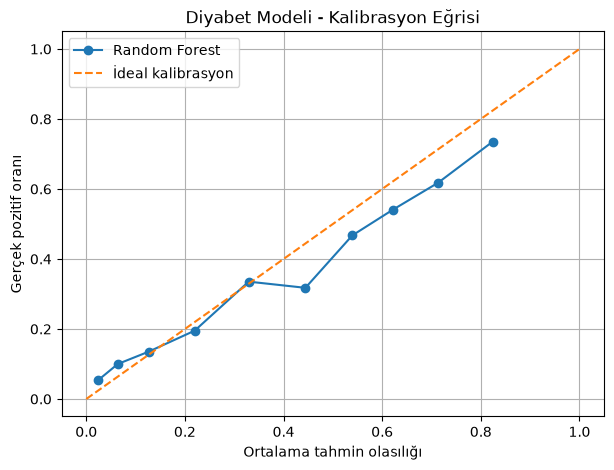

In [60]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    y_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="İdeal kalibrasyon"
)

plt.xlabel("Ortalama tahmin olasılığı")
plt.ylabel("Gerçek pozitif oranı")
plt.title("Diyabet Modeli - Kalibrasyon Eğrisi")
plt.legend()
plt.grid(True)
plt.show()

In [61]:
import pandas as pd

disease_targets = {
    "Diyabet": "DIQ010",
    "Hipertansiyon": "BPQ020",
    "Yüksek kolesterol": "BPQ080",
    "Artrit": "MCQ160A",
    "Kalp yetmezliği": "MCQ160B",
    "Koroner kalp hastalığı": "MCQ160C",
    "Anjina": "MCQ160D",
    "Kalp krizi": "MCQ160E",
    "İnme": "MCQ160F",
    "Kronik bronşit": "MCQ160L",
    "Tiroid problemi": "MCQ160M",
    "Karaciğer hastalığı": "MCQ160P",
    "Kanser öyküsü": "MCQ220"
}

results = []

for disease, target in disease_targets.items():
    if target not in merged_df.columns:
        continue

    y = merged_df[target]
    valid = y.isin([1, 2])

    yes_count = (y == 1).sum()
    no_count = (y == 2).sum()
    valid_count = valid.sum()

    results.append({
        "Hastalık": disease,
        "Hedef": target,
        "Geçerli kayıt": int(valid_count),
        "Pozitif": int(yes_count),
        "Negatif": int(no_count),
        "Pozitif oranı (%)": round(
            100 * yes_count / valid_count, 2
        ) if valid_count else 0,
        "Eksik/geçersiz": int((~valid).sum())
    })

disease_summary = pd.DataFrame(results)
display(
    disease_summary.sort_values(
        "Geçerli kayıt", ascending=False
    ).reset_index(drop=True)
)

,Hastalık,Hedef,Geçerli kayıt,Pozitif,Negatif,Pozitif oranı (%),Eksik/geçersiz
0,Diyabet,DIQ010,11452,1081,10371,9.44,481
1,Hipertansiyon,BPQ020,8487,2969,5518,34.98,3446
2,Yüksek kolesterol,BPQ080,8444,3096,5348,36.67,3489
3,Kanser öyküsü,MCQ220,7800,1169,6631,14.99,4133
4,Kalp krizi,MCQ160E,7794,332,7462,4.26,4139
5,Kronik bronşit,MCQ160L,7794,425,7369,5.45,4139
6,Karaciğer hastalığı,MCQ160P,7793,567,7226,7.28,4140
7,Kalp yetmezliği,MCQ160B,7791,343,7448,4.40,4142
8,Artrit,MCQ160A,7790,2532,5258,32.50,4143
9,Tiroid problemi,MCQ160M,7787,1053,6734,13.52,4146


In [62]:
import pandas as pd

targets = {
    "Diyabet": "DIQ010",
    "Hipertansiyon": "BPQ020",
    "Yüksek kolesterol": "BPQ080",
    "Artrit": "MCQ160A"
}

feature_cols = [
    "RIDAGEYR",
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "INDFMPIR",
    "BMXBMI",
    "BMXWAIST",
    "SLD012",
    "SMQ020"
]

rows = []

for disease, target in targets.items():
    valid_target = merged_df[target].isin([1, 2])
    valid_count = valid_target.sum()

    # Bu hastalık için hedefi geçerli olan katılımcılar
    disease_df = merged_df.loc[valid_target]

    # En az bir ortak özellik eksik olan satırları say
    missing_any = disease_df[feature_cols].isna().any(axis=1)

    rows.append({
        "Hastalık": disease,
        "Geçerli hedef": int(valid_count),
        "Ortak özelliklerde eksik olan": int(missing_any.sum()),
        "Tüm özellikleri dolu": int((~missing_any).sum())
    })

common_feature_summary = pd.DataFrame(rows)
display(common_feature_summary)

,Hastalık,Geçerli hedef,Ortak özelliklerde eksik olan,Tüm özellikleri dolu
0,Diyabet,11452,6662,4790
1,Hipertansiyon,8487,3520,4967
2,Yüksek kolesterol,8444,3499,4945
3,Artrit,7790,2825,4965


In [63]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

targets = {
    "Diyabet": "DIQ010",
    "Hipertansiyon": "BPQ020",
    "Yüksek kolesterol": "BPQ080",
    "Artrit": "MCQ160A"
}

feature_cols = [
    "RIDAGEYR", "RIAGENDR", "RIDRETH3",
    "DMDEDUC2", "INDFMPIR", "BMXBMI",
    "BMXWAIST", "SLD012", "SMQ020"
]

numeric_features = [
    "RIDAGEYR", "INDFMPIR",
    "BMXBMI", "BMXWAIST", "SLD012"
]

categorical_features = [
    "RIAGENDR", "RIDRETH3",
    "DMDEDUC2", "SMQ020"
]

models = {}
results = []

for disease, target in targets.items():

    # Yalnızca hedefi geçerli kayıtları kullan
    data = merged_df.loc[
        merged_df[target].isin([1, 2]),
        feature_cols + [target]
    ].copy()

    X = data[feature_cols].copy()
    y = data[target].map({1: 1, 2: 0}).astype(int)

    # Özel eksik kodlarını temizle
    for col in ["DMDEDUC2", "SMQ020"]:
        X[col] = X[col].replace([7, 9], np.nan)

    # Ön işleme
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    models[disease] = model

    results.append({
        "Hastalık": disease,
        "Eğitim kayıtları": len(X_train),
        "Test kayıtları": len(X_test),
        "Pozitif oranı (%)": round(y.mean() * 100, 2),
        "Accuracy": round(accuracy_score(y_test, y_pred), 3),
        "Precision": round(
            precision_score(y_test, y_pred, zero_division=0), 3
        ),
        "Recall": round(
            recall_score(y_test, y_pred, zero_division=0), 3
        ),
        "F1": round(
            f1_score(y_test, y_pred, zero_division=0), 3
        ),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 3)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Hastalık,Eğitim kayıtları,Test kayıtları,Pozitif oranı (%),Accuracy,Precision,Recall,F1,ROC-AUC
0,Diyabet,9161,2291,9.44,0.876,0.344,0.343,0.343,0.830
1,Hipertansiyon,6789,1698,34.98,0.693,0.549,0.687,0.610,0.759
2,Yüksek kolesterol,6755,1689,36.67,0.687,0.560,0.682,0.615,0.745
3,Artrit,6232,1558,32.50,0.716,0.552,0.670,0.605,0.784


In [65]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
threshold_results = []

for disease, target in targets.items():
    data = merged_df.loc[
        merged_df[target].isin([1, 2]),
        feature_cols + [target]
    ].copy()

    X = data[feature_cols].copy()
    y = data[target].map({1: 1, 2: 0}).astype(int)

    for col in ["DMDEDUC2", "SMQ020"]:
        X[col] = X[col].replace([7, 9], float("nan"))

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )

    model = models[disease]
    y_prob = model.predict_proba(X_test)[:, 1]

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)

        threshold_results.append({
            "Hastalık": disease,
            "Eşik": threshold,
            "Precision": precision_score(
                y_test, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_test, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_test, y_pred, zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))


,Hastalık,Eşik,Precision,Recall,F1
0,Diyabet,0.2,0.223,0.764,0.345
1,Diyabet,0.3,0.250,0.625,0.357
2,Diyabet,0.4,0.293,0.500,0.370
3,Diyabet,0.5,0.341,0.343,0.342
4,Diyabet,0.6,0.316,0.171,0.222
5,Diyabet,0.7,0.350,0.065,0.109
6,Hipertansiyon,0.2,0.451,0.921,0.606
7,Hipertansiyon,0.3,0.492,0.879,0.630
8,Hipertansiyon,0.4,0.529,0.811,0.640
9,Hipertansiyon,0.5,0.550,0.689,0.611


In [66]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Eşik seçimi için kullanılacak değerler
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

# Sonuçları saklayacağımız sözlükler
models = {}
validation_data = {}
test_data = {}
threshold_results = []

for disease, target in targets.items():

    # 1. Geçerli hedef etiketlerini seç
    data = merged_df.loc[
        merged_df[target].isin([1, 2]),
        feature_cols + [target]
    ].copy()

    X = data[feature_cols].copy()
    y = data[target].map({1: 1, 2: 0}).astype(int)

    # Özel kodları eksik değer olarak ele al
    for col in ["DMDEDUC2", "SMQ020"]:
        X[col] = X[col].replace([7, 9], np.nan)

    # 2. Önce test kümesini ayır (%20)
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    # Kalan %80'in %25'i = toplam verinin %20'si
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp,
        test_size=0.25,
        random_state=42,
        stratify=y_temp
    )

    # 3. Veri ön işleme
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    # 4. Model
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Yalnızca eğitim verisiyle öğren
    model.fit(X_train, y_train)

    # Modelleri ve ayrılmış verileri sakla
    models[disease] = model
    validation_data[disease] = (X_val, y_val)
    test_data[disease] = (X_test, y_test)

    # 5. Eşikleri yalnızca doğrulama kümesinde karşılaştır
    val_prob = model.predict_proba(X_val)[:, 1]

    for threshold in thresholds:
        val_pred = (val_prob >= threshold).astype(int)

        threshold_results.append({
            "Hastalık": disease,
            "Eşik": threshold,
            "Precision": precision_score(
                y_val, val_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_val, val_pred, zero_division=0
            ),
            "F1": f1_score(
                y_val, val_pred, zero_division=0
            )
        })

    print(
        f"{disease}: Eğitim={len(X_train)}, "
        f"Doğrulama={len(X_val)}, Test={len(X_test)}"
    )

threshold_df = pd.DataFrame(threshold_results)

print("\nDoğrulama sonuçları:")
display(threshold_df.round(3))


Diyabet: Eğitim=6870, Doğrulama=2291, Test=2291
Hipertansiyon: Eğitim=5091, Doğrulama=1698, Test=1698
Yüksek kolesterol: Eğitim=5066, Doğrulama=1689, Test=1689
Artrit: Eğitim=4674, Doğrulama=1558, Test=1558

Doğrulama sonuçları:


,Hastalık,Eşik,Precision,Recall,F1
0,Diyabet,0.2,0.239,0.861,0.374
1,Diyabet,0.3,0.283,0.699,0.403
2,Diyabet,0.4,0.339,0.537,0.416
3,Diyabet,0.5,0.337,0.273,0.302
4,Diyabet,0.6,0.343,0.111,0.168
5,Diyabet,0.7,0.381,0.037,0.068
6,Hipertansiyon,0.2,0.459,0.934,0.616
7,Hipertansiyon,0.3,0.511,0.882,0.647
8,Hipertansiyon,0.4,0.550,0.795,0.650
9,Hipertansiyon,0.5,0.584,0.658,0.619


In [67]:

best_thresholds = (
    threshold_df
    .sort_values("F1", ascending=False)
    .groupby("Hastalık")
    .first()
    .reset_index()
)

print("Doğrulama kümesine göre seçilen eşikler:")
display(best_thresholds.round(3))


Doğrulama kümesine göre seçilen eşikler:


,Hastalık,Eşik,Precision,Recall,F1
0,Artrit,0.4,0.503,0.814,0.622
1,Diyabet,0.4,0.339,0.537,0.416
2,Hipertansiyon,0.4,0.550,0.795,0.650
3,Yüksek kolesterol,0.4,0.530,0.800,0.637


In [68]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

final_results = []

# Doğrulama kümesinde seçilmiş eşikler
selected_thresholds = {
    row["Hastalık"]: row["Eşik"]
    for _, row in best_thresholds.iterrows()
}

for disease, model in models.items():
    X_test, y_test = test_data[disease]

    # Pozitif sınıf olasılıkları
    y_prob = model.predict_proba(X_test)[:, 1]

    # Doğrulama kümesinde seçilen eşiği uygula
    threshold = selected_thresholds[disease]
    y_pred = (y_prob >= threshold).astype(int)

    final_results.append({
        "Hastalık": disease,
        "Eşik": threshold,
        "Test kayıtları": len(y_test),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

final_results_df = pd.DataFrame(final_results)

display(final_results_df.round(3))


,Hastalık,Eşik,Test kayıtları,Accuracy,Precision,Recall,F1,ROC-AUC
0,Diyabet,0.4,2291,0.838,0.282,0.468,0.352,0.828
1,Hipertansiyon,0.4,1698,0.675,0.523,0.800,0.632,0.760
2,Yüksek kolesterol,0.4,1689,0.663,0.526,0.796,0.634,0.741
3,Artrit,0.4,1558,0.689,0.513,0.798,0.625,0.780


In [69]:

# İlk ve ikinci gün beslenme verilerinin sütunlarını incele

print("İlk gün beslenme verileri:")
display(pd.DataFrame({
    "Sütun": dr1_df.columns
}))

print("İkinci gün beslenme verileri:")
display(pd.DataFrame({
    "Sütun": dr2_df.columns
}))


İlk gün beslenme verileri:


NameError: name 'dr1_df' is not defined

In [70]:

import pandas as pd

dr1_df = pd.read_sas(
    "DR1TOT_L.xpt",
    format="xport"
)

dr2_df = pd.read_sas(
    "DR2TOT_L.xpt",
    format="xport"
)

print("İlk gün:", dr1_df.shape)
print("İkinci gün:", dr2_df.shape)


İlk gün: (8860, 168)
İkinci gün: (8860, 85)


In [71]:

print("İlk gün beslenme sütunları:")
print(dr1_df.columns.tolist())

print("\nİkinci gün beslenme sütunları:")
print(dr2_df.columns.tolist())


İlk gün beslenme sütunları:
['SEQN', 'WTDRD1', 'WTDR2D', 'DR1DRSTZ', 'DR1EXMER', 'DRABF', 'DRDINT', 'DR1DBIH', 'DR1DAY', 'DR1LANG', 'DR1MRESP', 'DR1HELP', 'DBQ095Z', 'DBD100', 'DRQSPREP', 'DR1STY', 'DR1SKY', 'DRQSDIET', 'DRQSDT1', 'DRQSDT2', 'DRQSDT3', 'DRQSDT4', 'DRQSDT5', 'DRQSDT6', 'DRQSDT7', 'DRQSDT8', 'DRQSDT9', 'DRQSDT10', 'DRQSDT11', 'DRQSDT12', 'DRQSDT91', 'DR1TNUMF', 'DR1TKCAL', 'DR1TPROT', 'DR1TCARB', 'DR1TSUGR', 'DR1TFIBE', 'DR1TTFAT', 'DR1TSFAT', 'DR1TMFAT', 'DR1TPFAT', 'DR1TCHOL', 'DR1TATOC', 'DR1TATOA', 'DR1TRET', 'DR1TVARA', 'DR1TACAR', 'DR1TBCAR', 'DR1TCRYP', 'DR1TLYCO', 'DR1TLZ', 'DR1TVB1', 'DR1TVB2', 'DR1TNIAC', 'DR1TVB6', 'DR1TFOLA', 'DR1TFA', 'DR1TFF', 'DR1TFDFE', 'DR1TCHL', 'DR1TVB12', 'DR1TB12A', 'DR1TVC', 'DR1TVD', 'DR1TVK', 'DR1TCALC', 'DR1TPHOS', 'DR1TMAGN', 'DR1TIRON', 'DR1TZINC', 'DR1TCOPP', 'DR1TSODI', 'DR1TPOTA', 'DR1TSELE', 'DR1TCAFF', 'DR1TTHEO', 'DR1TALCO', 'DR1TMOIS', 'DR1TS040', 'DR1TS060', 'DR1TS080', 'DR1TS100', 'DR1TS120', 'DR1TS140', 'DR1TS160', 'D

In [72]:

diet_cols = [
    "SEQN",
    "DR1TKCAL",
    "DR1TPROT",
    "DR1TCARB",
    "DR1TSUGR",
    "DR1TFIBE",
    "DR1TTFAT",
    "DR1TSFAT",
    "DR1TSODI",
    "DR1TNUMF"
]

diet_df = dr1_df[diet_cols].copy()

print("Beslenme verisi:", diet_df.shape)
display(diet_df.head())


Beslenme verisi: (8860, 10)


,SEQN,DR1TKCAL,DR1TPROT,DR1TCARB,DR1TSUGR,DR1TFIBE,DR1TTFAT,DR1TSFAT,DR1TSODI,DR1TNUMF
0,130378.0,1740.0,80.46,169.66,43.71,10.1,55.07,21.000,2628.0,17.0
1,130379.0,2741.0,86.45,314.86,113.58,29.6,67.18,14.544,5635.0,21.0
2,130380.0,1995.0,69.86,281.67,114.66,21.1,65.38,26.936,2890.0,18.0
3,130381.0,1676.0,54.11,224.98,117.83,11.5,63.57,22.004,2777.0,21.0
4,130382.0,1222.0,29.14,194.30,112.99,13.8,39.80,8.242,1288.0,18.0


In [73]:

print("Ana veri setinde SEQN benzersiz mi?:",
      merged_df["SEQN"].is_unique)

print("Beslenme verisinde SEQN benzersiz mi?:",
      diet_df["SEQN"].is_unique)

print("\nBeslenme sütunlarındaki eksik değerler:")
display(
    diet_df.drop(columns="SEQN")
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .rename("Eksik oranı (%)")
    .to_frame()
)


Ana veri setinde SEQN benzersiz mi?: True
Beslenme verisinde SEQN benzersiz mi?: True

Beslenme sütunlarındaki eksik değerler:


,Eksik oranı (%)
DR1TKCAL,24.45
DR1TPROT,24.45
DR1TCARB,24.45
DR1TSUGR,24.45
DR1TFIBE,24.45
DR1TTFAT,24.45
DR1TSFAT,24.45
DR1TSODI,24.45
DR1TNUMF,23.77


In [74]:

merged_diet_df = merged_df.merge(
    diet_df,
    on="SEQN",
    how="left",
    validate="one_to_one"
)

print("Ana veri seti:", merged_df.shape)
print("Beslenme eklenmiş veri seti:", merged_diet_df.shape)

print(
    "\nBeslenme verisi bulunan katılımcı:",
    merged_diet_df["DR1TKCAL"].notna().sum()
)

print(
    "Toplam katılımcı:",
    len(merged_diet_df)
)

display(
    merged_diet_df[
        ["SEQN", "DR1TKCAL", "DR1TPROT",
         "DR1TCARB", "DR1TSUGR", "DR1TFIBE"]
    ].head()
)


Ana veri seti: (11933, 124)
Beslenme eklenmiş veri seti: (11933, 133)

Beslenme verisi bulunan katılımcı: 6694
Toplam katılımcı: 11933


,SEQN,DR1TKCAL,DR1TPROT,DR1TCARB,DR1TSUGR,DR1TFIBE
0,130378.0,1740.0,80.46,169.66,43.71,10.1
1,130379.0,2741.0,86.45,314.86,113.58,29.6
2,130380.0,1995.0,69.86,281.67,114.66,21.1
3,130381.0,1676.0,54.11,224.98,117.83,11.5
4,130382.0,1222.0,29.14,194.30,112.99,13.8


In [75]:

# Önceki 9 özellik + 5 beslenme özelliği
diet_features = [
    "DR1TKCAL",
    "DR1TPROT",
    "DR1TCARB",
    "DR1TSUGR",
    "DR1TFIBE"
]

diet_feature_cols = feature_cols + diet_features

# Sayısal özelliklere beslenme sütunlarını ekle
diet_numeric_features = numeric_features + diet_features

print("Toplam özellik sayısı:", len(diet_feature_cols))
print("Kullanılan özellikler:")
print(diet_feature_cols)


Toplam özellik sayısı: 14
Kullanılan özellikler:
['RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'DMDEDUC2', 'INDFMPIR', 'BMXBMI', 'BMXWAIST', 'SLD012', 'SMQ020', 'DR1TKCAL', 'DR1TPROT', 'DR1TCARB', 'DR1TSUGR', 'DR1TFIBE']


In [76]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, accuracy_score
)

import numpy as np
import pandas as pd

targets = {
    "Diyabet": "DIQ010",
    "Hipertansiyon": "BPQ020",
    "Yüksek kolesterol": "BPQ080",
    "Artrit": "MCQ160A"
}

categorical_cols = [
    "RIAGENDR", "RIDRETH3", "DMDEDUC2", "SMQ020"
]

numeric_base = [
    "RIDAGEYR", "INDFMPIR", "BMXBMI",
    "BMXWAIST", "SLD012"
]

numeric_diet = numeric_base + diet_features

feature_sets = {
    "9 özellik": (feature_cols, numeric_base),
    "14 özellik": (diet_feature_cols, numeric_diet)
}

comparison_results = []
comparison_models = {}
comparison_thresholds = {}

for disease, target in targets.items():

    # İki modelde de aynı katılımcılar kullanılsın
    required_cols = list(dict.fromkeys(
        diet_feature_cols + [target]
    ))

    data = merged_diet_df.loc[
        merged_diet_df[target].isin([1, 2]),
        required_cols
    ].copy()

    # Beslenme verisi eksik olan katılımcıları karşılaştırmadan çıkar
    data = data.dropna(subset=diet_features)

    X_all = data[diet_feature_cols].copy()
    y_all = data[target].map({1: 1, 2: 0}).astype(int)

    for col in ["DMDEDUC2", "SMQ020"]:
        X_all[col] = X_all[col].replace([7, 9], np.nan)

    # Aynı katılımcılar için tek bir bölme oluştur
    X_temp, X_test, y_temp, y_test = train_test_split(
        X_all, y_all,
        test_size=0.20,
        random_state=42,
        stratify=y_all
    )

    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp,
        test_size=0.25,
        random_state=42,
        stratify=y_temp
    )

    for model_name, (features, numeric_cols) in feature_sets.items():

        cat_cols = [c for c in categorical_cols if c in features]

        preprocessor = ColumnTransformer([
            ("numeric", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), numeric_cols),
            ("categorical", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]), cat_cols)
        ])

        model = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ))
        ])

        model.fit(
            X_train[features],
            y_train
        )

        # Eşiği doğrulama kümesinde seç
        val_prob = model.predict_proba(X_val[features])[:, 1]

        threshold_scores = []
        for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
            val_pred = (val_prob >= threshold).astype(int)
            threshold_scores.append((
                f1_score(y_val, val_pred, zero_division=0),
                threshold
            ))

        best_f1, best_threshold = max(threshold_scores)

        # Test kümesi yalnızca nihai değerlendirmede kullanılır
        test_prob = model.predict_proba(X_test[features])[:, 1]
        test_pred = (test_prob >= best_threshold).astype(int)

        comparison_results.append({
            "Hastalık": disease,
            "Model": model_name,
            "Test kayıtları": len(y_test),
            "Eşik": best_threshold,
            "Accuracy": accuracy_score(y_test, test_pred),
            "Precision": precision_score(
                y_test, test_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_test, test_pred, zero_division=0
            ),
            "F1": f1_score(y_test, test_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, test_prob)
        })

        comparison_models[(disease, model_name)] = model
        comparison_thresholds[(disease, model_name)] = best_threshold

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.sort_values(["Hastalık", "Model"]).round(3)
)


,Hastalık,Model,Test kayıtları,Eşik,Accuracy,Precision,Recall,F1,ROC-AUC
7,Artrit,14 özellik,958,0.4,0.687,0.546,0.807,0.651,0.764
6,Artrit,9 özellik,958,0.3,0.657,0.516,0.859,0.644,0.760
1,Diyabet,14 özellik,1292,0.3,0.772,0.276,0.696,0.395,0.829
0,Diyabet,9 özellik,1292,0.3,0.761,0.267,0.710,0.388,0.832
3,Hipertansiyon,14 özellik,1035,0.4,0.701,0.565,0.805,0.664,0.793
2,Hipertansiyon,9 özellik,1035,0.4,0.704,0.567,0.810,0.667,0.781
5,Yüksek kolesterol,14 özellik,1031,0.4,0.668,0.565,0.837,0.674,0.743
4,Yüksek kolesterol,9 özellik,1031,0.3,0.641,0.537,0.908,0.675,0.733


In [77]:

import pandas as pd

importance_results = []

for (disease, model_name), model in comparison_models.items():

    # Şimdilik beslenme özellikli modelleri incele
    if model_name != "14 özellik":
        continue

    preprocessor = model.named_steps["preprocessor"]
    classifier = model.named_steps["classifier"]

    # Dönüştürülmüş sütunların adları
    transformed_names = preprocessor.get_feature_names_out()

    # Her dönüştürülmüş sütunun önem değeri
    importances = classifier.feature_importances_

    for transformed_name, importance in zip(
        transformed_names, importances
    ):
        # Örn. numeric__DR1TKCAL -> DR1TKCAL
        original_name = transformed_name.split("__", 1)[-1]

        importance_results.append({
            "Hastalık": disease,
            "Özellik": original_name,
            "Önem": importance
        })

importance_df = pd.DataFrame(importance_results)

# Sayısal ve kategorik özellikleri orijinal değişken bazında grupla
importance_grouped = (
    importance_df
    .groupby(["Hastalık", "Özellik"], as_index=False)["Önem"]
    .sum()
)

# Her hastalık için en önemli 10 özellik
for disease in importance_grouped["Hastalık"].unique():
    print(f"\n--- {disease}: En önemli 10 özellik ---")

    display(
        importance_grouped[
            importance_grouped["Hastalık"] == disease
        ]
        .sort_values("Önem", ascending=False)
        .head(10)
        .round(4)
    )



--- Artrit: En önemli 10 özellik ---


,Hastalık,Özellik,Önem
15,Artrit,RIDAGEYR,0.2299
1,Artrit,BMXWAIST,0.0924
0,Artrit,BMXBMI,0.0827
10,Artrit,DR1TPROT,0.0791
8,Artrit,DR1TFIBE,0.0749
11,Artrit,DR1TSUGR,0.0733
9,Artrit,DR1TKCAL,0.0732
7,Artrit,DR1TCARB,0.0713
12,Artrit,INDFMPIR,0.0590
22,Artrit,SLD012,0.0497



--- Diyabet: En önemli 10 özellik ---


,Hastalık,Özellik,Önem
40,Diyabet,RIDAGEYR,0.1997
26,Diyabet,BMXWAIST,0.1287
25,Diyabet,BMXBMI,0.1042
36,Diyabet,DR1TSUGR,0.0640
33,Diyabet,DR1TFIBE,0.0621
35,Diyabet,DR1TPROT,0.0600
32,Diyabet,DR1TCARB,0.0581
37,Diyabet,INDFMPIR,0.0580
34,Diyabet,DR1TKCAL,0.0556
31,Diyabet,DMDEDUC2_5.0,0.0517



--- Hipertansiyon: En önemli 10 özellik ---


,Hastalık,Özellik,Önem
65,Hipertansiyon,RIDAGEYR,0.2033
51,Hipertansiyon,BMXWAIST,0.1132
50,Hipertansiyon,BMXBMI,0.0952
61,Hipertansiyon,DR1TSUGR,0.0744
58,Hipertansiyon,DR1TFIBE,0.0742
60,Hipertansiyon,DR1TPROT,0.0740
57,Hipertansiyon,DR1TCARB,0.0716
59,Hipertansiyon,DR1TKCAL,0.0690
62,Hipertansiyon,INDFMPIR,0.0612
72,Hipertansiyon,SLD012,0.0477



--- Yüksek kolesterol: En önemli 10 özellik ---


,Hastalık,Özellik,Önem
90,Yüksek kolesterol,RIDAGEYR,0.2050
76,Yüksek kolesterol,BMXWAIST,0.0970
75,Yüksek kolesterol,BMXBMI,0.0867
82,Yüksek kolesterol,DR1TCARB,0.0789
86,Yüksek kolesterol,DR1TSUGR,0.0780
85,Yüksek kolesterol,DR1TPROT,0.0770
83,Yüksek kolesterol,DR1TFIBE,0.0752
84,Yüksek kolesterol,DR1TKCAL,0.0741
87,Yüksek kolesterol,INDFMPIR,0.0651
97,Yüksek kolesterol,SLD012,0.0500
